# Locked In: Mortgage Prepayment Behavior Across Rate Regimes

**Author:** Roberto Albornoz Martinez  
**Program:** M.S. Business Analytics, Boston University Questrom School of Business  
**Course:** BA889 — Analytics Practicum  
**Date:** July 2026

---

## Research Question

How does refinance incentive drive voluntary mortgage prepayment across opposite
interest-rate regimes, and does a prepayment model calibrated on one regime
transfer to the other?

## Motivation

Two groups of American mortgage borrowers, separated by only two years, ended
up living opposite financial stories.

The **2018 vintage** originated at an average rate of 4.74%. When mortgage
rates collapsed below 3% in 2020-21, these borrowers were handed the strongest
refinancing incentive in a generation - and 78.9% of them took it, prepaying
their loans.

The **2020 vintage** originated at an average of 3.19%. When rates climbed
above 6% from 2022 onward, these borrowers found themselves holding loans far
cheaper than anything the market now offers. Only 36.9% have prepaid; the rest
are *locked in* to rates they may never see again - an effect at the centre of
current housing-finance research.

Prepayment models sit underneath the valuation of mortgage-backed securities
and the management of servicing portfolios. If a model calibrated in one rate
regime fails when the regime flips, the practical consequence is systematic
mispricing of those assets. This project measures how the refinance incentive
drives prepayment in each regime, and then asks the harder question: does a
model trained on one regime transfer to the other?

## Data

Freddie Mac Single-Family Loan-Level Dataset (SFLLD), academic sample: 50,000
randomly selected loans per full vintage year, with monthly performance histories
disclosed through September 30, 2025. Supplemented with the Freddie Mac Primary
Mortgage Market Survey (PMMS) 30-year fixed rate series to construct the
borrower-level refinance incentive.

## Notebook Structure

| Section | Contents |
|:---:|:---|
| **0** | Setup and configuration |
| **1** | Data ingestion |
| **2** | Schema - applying official column names |
| **3** | Cleaning and validation |
| **4** | Building the prepayment target |
| **5** | Feature engineering I - the rate incentive |
| **6** | Building the hazard panel |
| **7** | Feature engineering II - behaviour, equity, and loan characteristics |
| **8** | Exploratory data analysis |
| **9** | Modelling - logistic baseline and gradient boosting |
| **10** | Evaluation and the cross-regime transfer test |
| **11** | Interpretation |
| **12** | Exporting figures and tables |



# **Section 0 - Setup And Configuration**

In [125]:
# I centralise every import, file path, and project-level constant in this one
# cell. Nothing later in the notebook hard-codes a path: all downstream cells
# reference the constants defined here, so if I ever relocate the project I
# only edit this cell.

# --- Standard library -------------------------------------------------------
import os                      # filesystem paths and directory operations
import glob                    # locating files by name pattern (Section 2)
import re                      # pattern checks on loan identifiers (Section 2)
import zipfile                 # extraction of the Freddie Mac sample archives
import warnings                # suppression of non-critical library warnings

# --- Numerical and data handling -------------------------------------------
import numpy as np             # numerical arrays and vectorised operations
import pandas as pd            # tabular data structures; primary analysis tool

# --- Modelling stack --------------------------------------------------------
import joblib                                        # saving fitted models (Sections 9-11)
import statsmodels.api as sm                         # logit with SEs and p-values (Section 9)
from sklearn.ensemble import HistGradientBoostingClassifier   # main model (Section 9)
from sklearn.model_selection import GroupShuffleSplit         # loan-level splitting (Section 9)
from sklearn.metrics import roc_auc_score, average_precision_score   # evaluation (Sections 9-10)
from sklearn.inspection import permutation_importance, partial_dependence   # interpretation (Section 11)

# --- Visualisation ----------------------------------------------------------
import matplotlib.pyplot as plt   # base plotting engine
import seaborn as sns             # statistical plots layered over matplotlib

# --- Display configuration --------------------------------------------------
# Widen console output so that wide loan-level tables remain readable when the
# notebook is exported to PDF.
pd.set_option('display.max_columns', 100)   # show up to 100 columns
pd.set_option('display.width', 200)         # widen the line-wrap threshold
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')  # readable floats

# Suppress low-signal warnings (e.g. pandas dtype inference notices) that would
# otherwise clutter an exported document. Errors remain visible.
warnings.filterwarnings('ignore')

# Consistent figure styling across every chart in the paper.
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 6)   # default figure size in inches
plt.rcParams['figure.dpi'] = 110           # on-screen resolution
plt.rcParams['savefig.dpi'] = 300          # print-quality export resolution
plt.rcParams['font.size'] = 11

# --- Reproducibility --------------------------------------------------------
# A single seed governs every stochastic operation (sampling, train/test splits,
# model initialisation) so that results are exactly reproducible.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Project paths ----------------------------------------------------------
# DRIVE : permanent storage on Google Drive. Source archives live here and
#         persist between Colab sessions.
# WORK  : ephemeral local disk on the Colab VM. Extracted files live here
#         because local I/O is substantially faster than mounted-Drive I/O.
#         Cleared when the runtime disconnects - by design.
# OUT   : permanent storage for outputs (figures, tables, checkpoints) that
#         must survive a disconnect.
PROJECT_ROOT = '/content/drive/MyDrive/MSBA/Summer Semester/BA889'
DRIVE = f'{PROJECT_ROOT}/Data'
OUT   = f'{PROJECT_ROOT}/Output'
WORK  = '/content/data'

# --- Analysis constants -----------------------------------------------------
# Origination years under study. Chosen for their opposing refinance incentives:
# 2018 loans became in-the-money during the 2020-21 rate collapse; 2020 loans
# are out-of-the-money against the post-2022 rate environment.
VINTAGES = [2018, 2020]

# The Freddie Mac academic sample draws this many loans from each full vintage
# year. Used later to validate that files loaded completely.
EXPECTED_LOANS_PER_VINTAGE = 50_000

# --- Dependency verification ------------------------------------------------
# statsmodels : logistic regression with inferential statistics (standard
#               errors, p-values) for the paper's coefficient table.
# pyarrow     : Parquet engine used for intermediate checkpoints.
for _lib in ['statsmodels', 'pyarrow', 'sklearn']:
    try:
        __import__(_lib)
        print(f'  {_lib:<12} available')
    except ImportError:
        print(f'  {_lib:<12} MISSING - run: !pip install {_lib}')

print(f'\npandas {pd.__version__} | numpy {np.__version__}')
print(f'Vintages under analysis: {VINTAGES}')


  statsmodels  available
  pyarrow      available
  sklearn      available

pandas 2.2.3 | numpy 2.1.3
Vintages under analysis: [2018, 2020]



# **Section 1 - Data Ingestion**

I mount Google Drive, extract the Freddie Mac sample archives to local disk,
and run a raw load test to confirm the files are intact before any parsing
logic touches them.

The SFLLD text files are **pipe-delimited (`|`) and contain no header row** —
Freddie Mac strips it deliberately. All files are therefore read with
`header=None`, and column names are applied separately in Section 2 from the
official File Layout specification.

In [126]:
# @title **1.1 - Mount Google Drive**
#
# Colab runs on a remote virtual machine with no access to my own computer, so
# the source data has to come through Google Drive, which I mount here as a
# filesystem at /content/drive. Google asks me to authorise the connection the
# first time this runs in each session.
#

from google.colab import drive

drive.mount('/content/drive')

# Create the working and output directories if they do not already exist.
# exist_ok=True makes this cell safe to re-run.
os.makedirs(WORK, exist_ok=True)
os.makedirs(OUT,  exist_ok=True)

# Confirm the source directory resolves. A failure here almost always indicates
# a path typo — note that 'Summer Semester' contains a space.
if os.path.isdir(DRIVE):
    print(f'Source directory located:\n  {DRIVE}')
else:
    raise FileNotFoundError(
        f'Source directory not found: {DRIVE}\n'
        'Verify the folder path in Google Drive matches PROJECT_ROOT exactly.'
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Source directory located:
  /content/drive/MyDrive/MSBA/Summer Semester/BA889/Data


In [127]:
# @title **1.2 - Inventory Source Archives**
#
# Before extracting anything, I list what is actually sitting in the Drive
# data folder. This confirms my uploads completed, and it records the exact
# source files I used - part of the audit trail for reproducibility.

print(f'Contents of {DRIVE}\n' + '-' * 60)

drive_files = sorted(os.listdir(DRIVE))

for fname in drive_files:
    fpath = os.path.join(DRIVE, fname)
    if os.path.isfile(fpath):
        size_mb = os.path.getsize(fpath) / 1e6
        print(f'  {fname:<40} {size_mb:>10,.1f} MB')

# Identify the archives required for the two vintages under analysis.
required_archives = [f'sample_{v}.zip' for v in VINTAGES]
missing = [a for a in required_archives if a not in drive_files]

print('-' * 60)
if missing:
    raise FileNotFoundError(f'Required archives not found in Drive: {missing}')
print(f'All required archives present: {required_archives}')


Contents of /content/drive/MyDrive/MSBA/Summer Semester/BA889/Data
------------------------------------------------------------
  PMMS_history.csv                                0.1 MB
  file_layout_july_2026.xlsx                      0.0 MB
  sample_2007.zip                                42.8 MB
  sample_2018.zip                                31.1 MB
  sample_2020.zip                                37.0 MB
------------------------------------------------------------
All required archives present: ['sample_2018.zip', 'sample_2020.zip']


In [128]:
# @title **1.3 - Extract Archives to Local Disk**
#
# I extract the archives to the Colab machine's local disk rather than reading
# them straight from the mounted Drive. Drive access carries network latency
# on every read, and that becomes painful when parsing multi-million-row
# performance files.
#
# Each vintage archive contains two files:
#   sample_orig_<year>.txt  — origination records, one row per loan
#   sample_svcg_<year>.txt  — servicing records, one row per loan per month

for archive in required_archives:
    archive_path = os.path.join(DRIVE, archive)
    with zipfile.ZipFile(archive_path) as zf:
        contents = zf.namelist()          # inspect before extracting
        zf.extractall(WORK)
    print(f'{archive} → extracted {len(contents)} file(s): {contents}')

# Inventory the extracted files. Note the size asymmetry: servicing files are
# an order of magnitude larger than origination files because they contain one
# observation per loan-month rather than one per loan.
print(f'\nContents of {WORK}\n' + '-' * 60)

extracted = sorted(os.listdir(WORK))
for fname in extracted:
    size_mb = os.path.getsize(os.path.join(WORK, fname)) / 1e6
    print(f'  {fname:<40} {size_mb:>10,.1f} MB')


sample_2018.zip → extracted 2 file(s): ['sample_orig_2018.txt', 'sample_svcg_2018.txt']
sample_2020.zip → extracted 2 file(s): ['sample_orig_2020.txt', 'sample_svcg_2020.txt']

Contents of /content/data
------------------------------------------------------------
  sample_orig_2018.txt                            7.7 MB
  sample_orig_2020.txt                            7.6 MB
  sample_svcg_2018.txt                          172.4 MB
  sample_svcg_2020.txt                          201.5 MB


In [129]:
# @title **1.4 - Raw Load Test**

# I read each file with minimal assumptions to verify structural integrity
# before any cleaning or schema logic is applied. Three things I check:
#
#   1. The pipe delimiter parses correctly (a single-column result would mean
#      the wrong separator).
#   2. The origination files contain the expected 50,000 loans.
#   3. Column counts match across vintages, confirming both files follow the
#      same File Layout specification.
#
# I only sample the servicing files at this stage; the full read waits until
# Section 3, where I specify proper dtypes, which keeps memory under control.

# Map each expected file to its extracted path, keyed by (type, vintage).
paths = {
    (kind, v): os.path.join(WORK, f'sample_{kind}_{v}.txt')
    for kind in ['orig', 'svcg']
    for v in VINTAGES
}

# --- Origination files: load in full  ----------------------------------------
orig_raw = {}
for v in VINTAGES:
    orig_raw[v] = pd.read_csv(
        paths[('orig', v)],
        sep='|',              # Freddie Mac uses pipe delimiters
        header=None,          # no header row present in the source files
        low_memory=False      # read whole file before inferring dtypes
    )
    n_rows, n_cols = orig_raw[v].shape
    flag = 'OK' if n_rows == EXPECTED_LOANS_PER_VINTAGE else 'CHECK'
    print(f'orig {v}: {n_rows:>9,} rows x {n_cols:>3} columns   [{flag}]')

# --- Servicing files: sample the first 200,000 rows to confirm structure ----
svcg_peek = {}
for v in VINTAGES:
    svcg_peek[v] = pd.read_csv(
        paths[('svcg', v)],
        sep='|',
        header=None,
        nrows=200_000,        # structural check only, not a full load
        low_memory=False
    )
    n_rows, n_cols = svcg_peek[v].shape
    print(f'svcg {v}: {n_rows:>9,} rows x {n_cols:>3} columns   [sample]')

# --- Consistency check ------------------------------------------------------
# Both vintages must share an identical column count; a mismatch would indicate
# files drawn from different File Layout releases and would invalidate any
# comparison between them.
assert orig_raw[VINTAGES[0]].shape[1] == orig_raw[VINTAGES[1]].shape[1], \
    'Origination files have differing column counts — check layout versions.'
assert svcg_peek[VINTAGES[0]].shape[1] == svcg_peek[VINTAGES[1]].shape[1], \
    'Servicing files have differing column counts — check layout versions.'

print('\nColumn counts consistent across vintages.')
print(f'Origination: {orig_raw[VINTAGES[0]].shape[1]} columns')
print(f'Servicing:   {svcg_peek[VINTAGES[0]].shape[1]} columns')

# --- Visual inspection ------------------------------------------------------
# Columns are unnamed at this stage; names are applied in Section 2.
print('\nFirst three origination records (2018 vintage):')
orig_raw[2018].head(3)


orig 2018:    50,000 rows x  32 columns   [OK]
orig 2020:    50,000 rows x  32 columns   [OK]
svcg 2018:   200,000 rows x  32 columns   [sample]
svcg 2020:   200,000 rows x  32 columns   [sample]

Column counts consistent across vintages.
Origination: 32 columns
Servicing:   32 columns
[Printed sample records removed from the published notebook: Freddie Mac loan-level data is not redistributed.]


# **Section 2 - Schema: Applying Official Column Names**

In [130]:
# @title **2.0 - Locate and inspect the official File Layout workbook**

# The Freddie Mac files contain no header row, so columns currently arrive as
# integer positions 0..31. In this section I attach the official field names
# from the Freddie Mac "File Layout - Effective July 2026" specification, so
# that all downstream code refers to columns by name rather than by fragile
# position.
#
# An incorrect mapping would silently corrupt the entire analysis, so I read
# the names from the official workbook (authoritative) and then validate them
# against the actual data values before committing to them.

import glob                    # locating files by name pattern (Section 2)
import re                      # pattern checks on loan identifiers (Section 2)

# pandas reads .xlsx via openpyxl (present in Colab by default).
# If the read below errors with a missing-engine message, run: !pip install openpyxl

# Find every Excel file in the Data directory and identify the layout workbook.
xlsx_files = glob.glob(os.path.join(DRIVE, '*.xlsx'))
print('Excel files found in the Data directory:')
for f in xlsx_files:
    print('   ', os.path.basename(f))

# Prefer a file whose name contains "layout"; otherwise fall back to the first.
layout_path = next(
    (f for f in xlsx_files if 'layout' in os.path.basename(f).lower()),
    xlsx_files[0] if xlsx_files else None
)
if layout_path is None:
    raise FileNotFoundError('No .xlsx layout file found in the Data directory.')
print(f'\nUsing layout workbook: {os.path.basename(layout_path)}')

# Read ALL worksheets. sheet_name=None returns {sheet_name: DataFrame}. The
# layout workbook usually separates the origination and performance schemas
# onto different sheets. header=None keeps every row visible, including any
# title rows, so we can see exactly where the ordered field names live.
layout_sheets = pd.read_excel(layout_path, sheet_name=None, header=None)

print(f'\nWorksheets in the workbook ({len(layout_sheets)}):')
for name, df in layout_sheets.items():
    print(f'   "{name}"  ->  {df.shape[0]} rows x {df.shape[1]} cols')

# Show the top of each worksheet so its structure is visible.
for name, df in layout_sheets.items():
    print('\n' + '=' * 72)
    print(f'SHEET: {name}')
    print('=' * 72)
    print(df.head(20).to_string())


Excel files found in the Data directory:
    file_layout_july_2026.xlsx

Using layout workbook: file_layout_july_2026.xlsx

Worksheets in the workbook (2):
   "Origination Data File"  ->  33 rows x 4 cols
   "Monthly Performance Data File"  ->  37 rows x 4 cols

SHEET: Origination Data File
                        0                                                             1                   2           3
0   ORIGINATION DATA FILE                                                           NaN                 NaN         NaN
1          Field Position                                                Attribute Name  Data Type & Format  Max Length
2                       1                                                 Classic FICO®             Numeric           4
3                       2                                            First Payment Date                Date           6
4                       3                                First Time Homebuyer Indicator               Alpha 

In [131]:
# @title **2.1 - Inspect the raw servicing data for validation**

# Origination column order was already confirmed against real values in
# Section 1. The servicing file has not yet been eyeballed, so I display its
# first rows here. Seeing the actual values - reporting dates, balances,
# status codes - lets me confirm in 2.2 that each name lands on the correct
# column rather than trusting position alone. (svcg_peek was loaded in 1.4
# and is reused here.)

for v in VINTAGES:
    print('=' * 72)
    print(f'RAW SERVICING DATA - {v} vintage (first 5 rows, unnamed columns)')
    print('=' * 72)
    print(svcg_peek[v].head(5).to_string())
    print()


RAW SERVICING DATA - 2018 vintage (first 5 rows, unnamed columns)
             0       1           2  3   4    5   6    7   8   9      10     11  12  13  14  15  16  17  18  19  20  21  22   23   24  25  26  27   28   29  30          31
0  F18Q10000028  201802 50,000.0000  0   0  360 NaN  NaN NaN NaN 4.5000 0.0000 NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN  NaN  NaN  75 NaN NaN  NaN  NaN NaN 50,000.0000
1  F18Q10000028  201803 50,000.0000  0   1  359 NaN  NaN NaN NaN 4.5000 0.0000 NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN  NaN  NaN  76 NaN NaN  NaN  NaN NaN 50,000.0000
2  F18Q10000028  201804 50,000.0000  0   2  358 NaN  NaN NaN NaN 4.5000 0.0000 NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN  NaN  NaN  73 NaN NaN  NaN  NaN NaN 50,000.0000
3  F18Q10000028  201805 50,000.0000  0   3  357 NaN  NaN NaN NaN 4.5000 0.0000 NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN  NaN  NaN  47 NaN NaN  NaN  NaN NaN 50,000.0000
4  F18Q10000028  201806 50,000.0000  0   4  356 NaN  NaN NaN NaN 4.5000 0.0000 

In [132]:
# @title **2.2 - Reconcile layout field names against the actual data**

# The layout workbook and the sample data files are versioned differently, so
# their column counts do not match exactly. Rather than trust the document, I
# lay the layout's field names beside the real data values, column by column,
# and confirm alignment by inspection. Only the leading columns, which contain
# every field this project uses, need to align, and those are verifiable
# because their values (loan IDs, rates, balances) are self-identifying.

def extract_layout(df):
    """Return the ordered list of Attribute Names from a layout worksheet.

    The sheet has a title row and a column-header row before the field rows.
    I locate the header row by finding 'Attribute Name', then take every
    subsequent row whose Field Position is numeric.
    """
    hdr_idx = None
    for i in range(min(6, len(df))):
        if df.iloc[i].astype(str).str.strip().eq('Attribute Name').any():
            hdr_idx = i
            break
    if hdr_idx is None:
        raise ValueError('Could not find the header row in the layout sheet.')

    header = df.iloc[hdr_idx].astype(str).str.strip().tolist()
    pos_col = header.index('Field Position')
    name_col = header.index('Attribute Name')

    field_rows = df.iloc[hdr_idx + 1:]
    is_field = pd.to_numeric(field_rows[pos_col], errors='coerce').notna()
    return field_rows.loc[is_field, name_col].astype(str).str.strip().tolist()

orig_layout = extract_layout(layout_sheets['Origination Data File'])
svcg_layout = extract_layout(layout_sheets['Monthly Performance Data File'])

print(f'Origination - layout lists {len(orig_layout)} fields | data has {orig_raw[2018].shape[1]} columns')
print(f'Servicing   - layout lists {len(svcg_layout)} fields | data has {svcg_peek[2018].shape[1]} columns')

def reconcile(data_df, layout_names, label):
    """Print each data column beside a sample value and the layout name at
    that position, so alignment can be confirmed by eye."""
    rows = [{
        'data_col': i,
        'sample_value': data_df.iloc[0, i],
        'layout_name_at_position': layout_names[i] if i < len(layout_names) else '- (no layout field)'
    } for i in range(data_df.shape[1])]
    print(f'\n{label}\n' + '=' * 78)
    print(pd.DataFrame(rows).to_string(index=False))

reconcile(orig_raw[2018], orig_layout, 'ORIGINATION - column reconciliation')
reconcile(svcg_peek[2018], svcg_layout, 'SERVICING - column reconciliation')


Origination - layout lists 31 fields | data has 32 columns
Servicing   - layout lists 35 fields | data has 32 columns

ORIGINATION - column reconciliation
 data_col    sample_value                                      layout_name_at_position
        0             654                                                Classic FICO®
        1          201803                                           First Payment Date
        2               N                               First Time Homebuyer Indicator
        3          204802                                                Maturity Date
        4             NaN Metropolitan Statistical Area (MSA) Or Metropolitan Division
        5               0                         Mortgage Insurance Percentage (MI %)
        6               1                                              Number of Units
        7               P                                             Occupancy Status
        8              77                       Original Combi

In [133]:
# @title **2.3 - Assign verified names to the analysis columns**

# Positions below were confirmed against actual data values in Sections 1.4
# through 2.2 (e.g. the loan sequence number 'F18Q10000028', the 4.5% interest
# rate, the estimated LTV of 75 beside an original LTV of 77). I deliberately
# select only the fields the study requires rather than naming all 32 columns,
# which keeps the working data clean and sidesteps the sparse,
# version-dependent tail columns entirely.

# Data column index -> analysis name (origination file)
ORIG_COLS = {
    0:  'credit_score',
    1:  'first_payment_date',
    3:  'maturity_date',
    6:  'num_units',
    7:  'occupancy_status',
    8:  'orig_cltv',
    9:  'orig_dti',
    10: 'orig_upb',
    11: 'orig_ltv',
    12: 'orig_interest_rate',
    16: 'property_state',
    17: 'property_type',
    19: 'loan_sequence_number',
    20: 'loan_purpose',
    21: 'orig_loan_term',
}

# Data column index -> analysis name (servicing file)
SVCG_COLS = {
    0:  'loan_sequence_number',
    1:  'period',                          # monthly reporting period, YYYYMM
    2:  'current_actual_upb',
    3:  'delinquency_status',
    4:  'loan_age',
    5:  'remaining_months_to_maturity',
    8:  'zero_balance_code',               # the prepayment/termination signal
    9:  'zero_balance_date',
    10: 'current_interest_rate',
    25: 'eltv',                            # estimated current LTV - the equity constraint
    29: 'assistance_plan',                 # forbearance blocks refinancing
}

def apply_names(data_df, colmap):
    """Select the mapped columns by position and rename them."""
    out = data_df[list(colmap.keys())].copy()
    out.columns = list(colmap.values())
    return out

# Origination files are small - apply names to the full frames.
orig = {v: apply_names(orig_raw[v], ORIG_COLS) for v in VINTAGES}

# Servicing: name the 200k-row sample for validation now; the full files are
# loaded with explicit dtypes in Section 3.
svcg_sample = {v: apply_names(svcg_peek[v], SVCG_COLS) for v in VINTAGES}

# ---- Validation against anchor values --------------------------------------
# Hard checks on fields whose correctness is unambiguous; a failure here means a
# column is misaligned and must be fixed before proceeding.
seq_pattern = re.compile(r'^F\d{2}Q\d')     # e.g. F18Q1..., F20Q1...

for v in VINTAGES:
    o = orig[v]
    assert o['loan_sequence_number'].str.match(seq_pattern).all(), f'{v}: bad loan-seq format (orig)'
    assert o['loan_sequence_number'].is_unique,                    f'{v}: loan-seq not unique (orig)'
    assert (o['orig_upb'] > 0).all(),                              f'{v}: non-positive UPB (orig)'
    assert o['orig_interest_rate'].between(1, 10).mean() > 0.99,   f'{v}: rate out of range (orig)'

    # Two sample-homogeneity checks on raw columns I deliberately don't carry
    # forward. Position 15 is the Amortization Type and position 14 is the
    # Prepayment Penalty Indicator (both confirmed in the 2.2 reconciliation).
    # Every loan must be fixed-rate, because my rate incentive is computed
    # against the 30-year FIXED PMMS rate, which would be the wrong benchmark
    # for an adjustable loan. And no loan may carry a prepayment penalty,
    # which would suppress prepayment mechanically rather than economically.
    # Since both columns turn out to be constant, they have no predictive
    # value - so I verify them once here and never load them again.
    assert (orig_raw[v][15] == 'FRM').all(), f'{v}: non-fixed-rate loans present'
    assert (orig_raw[v][14] == 'N').all(),   f'{v}: prepayment penalties present'

    s = svcg_sample[v]
    assert s['loan_sequence_number'].str.match(seq_pattern).all(), f'{v}: bad loan-seq format (svcg)'
    assert s['period'].astype(str).str.len().eq(6).all(),          f'{v}: period not YYYYMM (svcg)'
    assert (s['current_actual_upb'] >= 0).all(),                   f'{v}: negative UPB (svcg)'

    join_rate = s['loan_sequence_number'].isin(o['loan_sequence_number']).mean()
    print(f'{v}: {len(o):,} loans | orig rate {o["orig_interest_rate"].mean():.3f}% | '
          f'svcg sample loans in origination: {join_rate*100:.1f}%')

print('\nAll anchor validations passed.')
print('Sample homogeneity confirmed: every loan is fixed-rate; none carries a prepayment penalty.')
print('\nOrigination (2018) named columns:')
print(orig[2018].head(3).to_string())


2018: 50,000 loans | orig rate 4.736% | svcg sample loans in origination: 100.0%
2020: 50,000 loans | orig rate 3.194% | svcg sample loans in origination: 100.0%

All anchor validations passed.
Sample homogeneity confirmed: every loan is fixed-rate; none carries a prepayment penalty.

Origination (2018) named columns:
   credit_score  first_payment_date  maturity_date  num_units occupancy_status  orig_cltv  orig_dti  orig_upb  orig_ltv  orig_interest_rate property_state property_type loan_sequence_number loan_purpose  orig_loan_term
0           654              201803         204802          1                P         77        35     50000        77              4.5000             KY            SF         F18Q10000028            P             360
1           693              201803         203302          1                P         80        41    132000        80              3.2500             MI            SF         F18Q10000052            P             180
2           757        

# **Section 3 - Cleaning and Validation**

This is where the project moves from setup into the data itself. I load the
full monthly performance files - every month of every loan - forcing each
column into its correct type, including reading the coded columns as text so
that a code like "01" survives intact instead of silently becoming the number 1. I then look at how loans actually ended, because those endings are the raw material for the prepayment target built in Section 4. The section closes with
a checkpoint, so the expensive parse never has to be repeated.

In [134]:
# @title **3.1 - Load the Full Performance Files**

# These are the big files: one row per loan for every month it stayed active.
# To keep them manageable I only read the columns I actually need, give each
# one a small data type, and this time I read all the rows. I need every month
# so I can see exactly when each loan pays off.

# The columns I want, by their position in the file -> the name I'll use.
SVCG_USE = {
    0:  'loan_sequence_number',        # links each monthly row back to its loan
    1:  'period',                      # the reporting month, written as YYYYMM
    2:  'current_actual_upb',          # how much of the loan is still owed
    3:  'delinquency_status',          # 0 = current, higher = months behind
    4:  'loan_age',                    # months since the loan started
    5:  'remaining_months_to_maturity',
    8:  'zero_balance_code',           # WHY the loan ended (blank until it ends)
    9:  'zero_balance_date',           # WHEN the loan ended
    10: 'current_interest_rate',       # the loan's interest rate that month
    25: 'eltv',                        # estimated current LTV - the equity constraint
    29: 'assistance_plan',             # forbearance blocks refinancing
}
positions = sorted(SVCG_USE)
names = [SVCG_USE[p] for p in positions]

# A lesson learned the hard way: the zero-balance code is blank on almost
# every row, so pandas assumed it was a number and turned "01" into 1.0 -
# which then never matched when I searched for "01". By forcing the coded
# columns to be read as TEXT from the start, "01" stays "01".
READ_AS_TEXT = {0: 'string', 3: 'string', 8: 'string', 9: 'string', 29: 'string'}

def load_performance(path):
    df = pd.read_csv(path, sep='|', header=None, usecols=positions,
                     dtype=READ_AS_TEXT, low_memory=False)
    df.columns = names

    # Shrink the numeric columns so the big files fit comfortably in memory.
    df['period']                       = df['period'].astype('int32')
    df['current_actual_upb']           = pd.to_numeric(df['current_actual_upb'], errors='coerce').astype('float32')
    df['loan_age']                     = pd.to_numeric(df['loan_age'], errors='coerce').astype('float32')
    df['remaining_months_to_maturity'] = pd.to_numeric(df['remaining_months_to_maturity'], errors='coerce').astype('float32')
    df['current_interest_rate']        = pd.to_numeric(df['current_interest_rate'], errors='coerce').astype('float32')

    # Estimated LTV: Freddie Mac's monthly estimate of the balance against the
    # home's CURRENT value, as a whole number (75 means 75%). There are no
    # blanks - instead 999 means "not available", and it is common (about 8%
    # of 2018 rows, concentrated in a loan's first months before the first
    # estimate exists). I convert 999 to missing so it can never be mistaken
    # for a real loan-to-value.
    df['eltv'] = pd.to_numeric(df['eltv'], errors='coerce').astype('float32')
    df.loc[df['eltv'] == 999, 'eltv'] = np.nan

    # Tidy the text columns (strip any stray spaces), and store the loan ID as
    # a category since the same 50,000 IDs repeat across millions of rows.
    # assistance_plan is F/R/T when the borrower is in forbearance, repayment,
    # or a trial modification that month - states in which refinancing is not
    # possible regardless of the rate incentive.
    df['zero_balance_code']    = df['zero_balance_code'].str.strip()
    df['zero_balance_date']    = df['zero_balance_date'].str.strip()
    df['delinquency_status']   = df['delinquency_status'].str.strip()
    df['assistance_plan']      = df['assistance_plan'].str.strip()
    df['loan_sequence_number'] = df['loan_sequence_number'].astype('category')
    return df

svcg = {}
for v in VINTAGES:
    svcg[v] = load_performance(paths[('svcg', v)])
    mem_mb = svcg[v].memory_usage(deep=True).sum() / 1e6
    print(f'{v}: {len(svcg[v]):>10,} loan-months | '
          f'{svcg[v]["loan_sequence_number"].nunique():>7,} loans | '
          f'{mem_mb:>7,.0f} MB in memory')


2018:  1,998,728 loan-months |  50,000 loans |     495 MB in memory
2020:  2,340,586 loan-months |  50,000 loans |     580 MB in memory


In [135]:
# @title **3.2 - Look at how loans ended, before I define "prepaid"**

# The zero-balance code tells me why each loan left the data. I want to see the
# real mix in my own files before I lock in what counts as a prepayment.
# Freddie Mac's meanings for the codes I expect to see:
#   01 = Prepaid or Matured    - paid off early (refinance or sale). This is my target.
#   02 = Third-Party Sale
#   03 = Short Sale / Charge-Off  \
#   09 = REO Disposition           }  default-related endings, not prepayment
#   15 / 16 = Note / Reperforming Sale
#   96 = Removal (e.g. repurchase)
# A blank code means the loan was still active when the data ends (Sept 2025).
#
# Note on my two cohorts: because these loans are only a few years old, none can
# have "matured" naturally (a 30-year loan from 2018 can't reach term by 2025),
# so code 01 here means a genuine early payoff — exactly the prepayment I study.

for v in VINTAGES:
    print(f'\n{v} vintage - how loans ended (number of loans by zero-balance code):')
    # The code only appears in a loan's final row, so I keep just the filled-in ones.
    ended = svcg[v].loc[
        svcg[v]['zero_balance_code'].notna(),
        ['loan_sequence_number', 'zero_balance_code']
    ]
    print(ended['zero_balance_code'].value_counts(dropna=False).to_string())

    total_loans  = svcg[v]['loan_sequence_number'].nunique()
    ended_loans  = ended['loan_sequence_number'].nunique()
    still_active = total_loans - ended_loans
    prepaid      = (ended['zero_balance_code'] == '01').sum()
    print(f'   prepaid (code 01):        {prepaid:>7,}  ({prepaid/total_loans*100:>4.1f}% of loans)')
    print(f'   still active at Sept 2025:{still_active:>7,}  ({still_active/total_loans*100:>4.1f}% of loans)')



2018 vintage - how loans ended (number of loans by zero-balance code):
zero_balance_code
01    39468
96      115
16       53
02       28
09       15
15       12
03        7
   prepaid (code 01):         39,468  (78.9% of loans)
   still active at Sept 2025: 10,302  (20.6% of loans)

2020 vintage - how loans ended (number of loans by zero-balance code):
zero_balance_code
01    18442
96      110
16       17
09        9
02        7
   prepaid (code 01):         18,442  (36.9% of loans)
   still active at Sept 2025: 31,415  (62.8% of loans)


### Section 3 - What the raw endings already show

Before any modelling, the raw termination codes reveal the effect this project
set out to study, and it is large.

Each loan's ending is recorded once, in its final month, by the zero-balance
code. Reading those codes across the two cohorts:

| Cohort | Origination rate | Prepaid (code 01) | Still active (Sep 2025) |
|---|---|---|---|
| **2018** | 4.74% | **39,468 (78.9%)** | 10,302 (20.6%) |
| **2020** | 3.19% | **18,442 (36.9%)** | 31,415 (62.8%) |

The 2018 cohort originated near 4.74% and became deeply *in-the-money* when
mortgage rates fell below 3% in 2020-2021: nearly four in five of these loans
prepaid. The 2020 cohort originated near 3.19% and is now *out-of-the-money*
against a market above 6%: fewer than four in ten prepaid, and the majority
are still active - the lock-in effect made visible.

The result is a **42-percentage-point gap in prepayment between the two rate
regimes, observed directly in the data before any model is fit.** The
modelling that follows therefore does not need to establish that a difference
exists; its task is to explain what drives it and to test whether a model
calibrated on one regime transfers to the other.

A small share of loans ended for reasons other than prepayment: default-related
dispositions and note sales (codes 02, 03, 09, 15, 16) and administrative
removals (code 96) - a few hundred loans per cohort. These are handled
explicitly when the prepayment target is constructed in Section 4.

In [136]:
# @title **3.3 - Checkpoint: save the cleaned frames to Drive**

# I've now done the expensive work: parsing millions of rows and typing them
# correctly. Before going further I save everything to Parquet so that if my
# Colab session disconnects, I can reload in seconds instead of re-parsing.
# Parquet keeps my data types and categories intact, unlike CSV.

os.makedirs(OUT, exist_ok=True)

for v in VINTAGES:
    orig_path = f'{OUT}/orig_{v}_clean.parquet'
    svcg_path = f'{OUT}/svcg_{v}_clean.parquet'
    orig[v].to_parquet(orig_path, index=False)
    svcg[v].to_parquet(svcg_path, index=False)
    print(f'{v}: saved origination ({len(orig[v]):,} rows) and '
          f'performance ({len(svcg[v]):,} rows)')

print('\nCheckpoint saved. To reload later without re-parsing:')
print("  orig = {v: pd.read_parquet(f'{OUT}/orig_{v}_clean.parquet') for v in VINTAGES}")
print("  svcg = {v: pd.read_parquet(f'{OUT}/svcg_{v}_clean.parquet') for v in VINTAGES}")


2018: saved origination (50,000 rows) and performance (1,998,728 rows)
2020: saved origination (50,000 rows) and performance (2,340,586 rows)

Checkpoint saved. To reload later without re-parsing:
  orig = {v: pd.read_parquet(f'{OUT}/orig_{v}_clean.parquet') for v in VINTAGES}
  svcg = {v: pd.read_parquet(f'{OUT}/svcg_{v}_clean.parquet') for v in VINTAGES}


# **Section 4 - Building the Prepayment Target**

I now turn the monthly performance panel (millions of loan-months) into one row per loan, labelled with whether it prepaid and, if so, when. This is a very important transformation in the project: it defines what I'm predicting.

In [137]:
# @title **4.1 - Find each loan's final month**

# Every loan's ending is recorded once, in its LAST monthly row - that is
# where the zero-balance code and date appear. So I sort each loan's months
# into order and keep the final row per loan, which collapses the monthly
# panel into one summary record per loan: its ending code, its final age,
# and its last observed balance and rate.

last_row = {}
for v in VINTAGES:
    df = svcg[v].sort_values(['loan_sequence_number', 'period'])
    last_row[v] = (df.groupby('loan_sequence_number', observed=True)
                     .last()
                     .reset_index())

    # Validation: the collapse must yield exactly one row per loan, with no
    # loan lost on the way. If this fails, nothing downstream can be trusted.
    assert len(last_row[v]) == svcg[v]['loan_sequence_number'].nunique(), \
        f'{v}: row count after collapse does not match loan count'
    print(f'{v}: {len(svcg[v]):>10,} loan-months collapsed to '
          f'{len(last_row[v]):>7,} final rows - one per loan')


2018:  1,998,728 loan-months collapsed to  50,000 final rows - one per loan
2020:  2,340,586 loan-months collapsed to  50,000 final rows - one per loan


In [138]:
# @title **4.2 - Define the outcome, following the competing-risks logic**

# I classify every loan into one of three outcomes based on how it ended:
#   - prepaid (code 01)                              - event of interest
#   - still active (no ending code by Sep 2025)      - genuine "did not prepay"
#   - ended another way (default / note-sale / admin)- competing event, excluded

DEFAULT_CODES = {'02', '03', '09', '15', '16'}   # non-prepay economic exits
ADMIN_CODES   = {'96'}                            # administrative removals

def classify(code):
    if pd.isna(code) or code == '':
        return 'active'          # never ended - stayed in the pool
    if code == '01':
        return 'prepaid'         # early payoff - my event
    if code in DEFAULT_CODES:
        return 'default_exit'    # competing event
    if code in ADMIN_CODES:
        return 'admin_exit'      # competing event (administrative)
    return 'other_exit'          # anything unexpected - flagged, not silently kept

target = {}
for v in VINTAGES:
    last = last_row[v].copy()

    last['outcome'] = last['zero_balance_code'].apply(classify)

    # Binary target: 1 if prepaid, 0 if it stayed active. Competing exits are
    # set to <NA> so they can be excluded from the binary model cleanly.
    last['prepaid'] = last['outcome'].map({'prepaid': 1, 'active': 0})

    # Timing target: the loan's age (in months) in its final row. For a
    # prepaid loan this is the age AT prepayment - the survival-style angle I
    # want to keep open. It's left as-is for non-prepaid loans (used only
    # where relevant).
    last['age_at_exit'] = last['loan_age']

    target[v] = last

    # ---- Report the composition so it's transparent for the paper -----------
    counts = last['outcome'].value_counts()
    n = len(last)
    print(f'\n{v} vintage - outcome composition ({n:,} loans):')
    for outcome, cnt in counts.items():
        print(f'   {outcome:<13} {cnt:>7,}  ({cnt/n*100:>4.1f}%)')

    modelled = last['prepaid'].notna().sum()
    excluded = n - modelled
    prepay_rate = last['prepaid'].mean()
    print(f'   --> modelled loans (prepaid vs active): {modelled:,}')
    print(f'   --> excluded (competing exits):         {excluded:,}')
    print(f'   --> prepayment rate among modelled:     {prepay_rate*100:.1f}%')



2018 vintage - outcome composition (50,000 loans):
   prepaid        39,468  (78.9%)
   active         10,302  (20.6%)
   admin_exit        115  ( 0.2%)
   default_exit      115  ( 0.2%)
   --> modelled loans (prepaid vs active): 49,770
   --> excluded (competing exits):         230
   --> prepayment rate among modelled:     79.3%

2020 vintage - outcome composition (50,000 loans):
   active         31,415  (62.8%)
   prepaid        18,442  (36.9%)
   admin_exit        110  ( 0.2%)
   default_exit       33  ( 0.1%)
   --> modelled loans (prepaid vs active): 49,857
   --> excluded (competing exits):         143
   --> prepayment rate among modelled:     37.0%


In [139]:
# @title **4.3 - Checkpoint the loan-level target table**

# I've collapsed millions of loan-months into one labelled row per loan. I
# save these target tables now so the collapse doesn't have to be repeated.

for v in VINTAGES:
    path = f'{OUT}/target_{v}.parquet'
    target[v].to_parquet(path, index=False)
    print(f'{v}: saved target table ({len(target[v]):,} loans) -> {path}')


2018: saved target table (50,000 loans) -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/target_2018.parquet
2020: saved target table (50,000 loans) -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/target_2020.parquet


### Section 4 - What the target shows

Every loan now carries a single label. Of 50,000 loans per vintage, 49,770 (2018) and 49,857 (2020) enter the analysis as either *prepaid* or *still active* - a 79.3% prepayment rate in the 2018 cohort against 37.0% in the 2020 cohort. The remaining 230 and 143 loans ended for reasons that are not prepayment: default-related dispositions and administrative removals. I exclude them rather than counting them as "did not prepay", because a loan that defaulted never got the chance to make the refinancing decision this project studies, keeping it would blur the very behaviour I am trying to measure. At under half a percent of each cohort, the exclusion cannot move the results. I also keep each loan's age at exit, which lets the analysis ask not just *whether* a loan prepaid but *when*, the question the rest of the project is built around.

# **Section 5 - Feature Engineering I: The Rate Incentive**

In this section I am building the single most important predictor in the project: how far each borrower's own mortgage rate sits above the prevailing market rate. That gap, the refinance incentive, is the mechanism behind the 79%-vs-37% split.

In [140]:
# @title **5.1 - Load the PMMS market-rate series and collapse it to monthly**

# My loan performance data is monthly (one row per loan per month), but PMMS is
# weekly. So I load PMMS, keep only the date and the 30-year rate, and average
# the weekly rates within each calendar month to get one market rate per month.
# That monthly market rate is what I'll line up against each loan-month.

pmms_path = f'{DRIVE}/PMMS_history.csv'

# I only need two columns: the week's date and the 30-year fixed rate (pmms30).
pmms = pd.read_csv(pmms_path, usecols=['date', 'pmms30'])

# Parse the date (format is M/D/YYYY) and make sure the rate is numeric.
pmms['date']   = pd.to_datetime(pmms['date'], format='%m/%d/%Y', errors='coerce')
pmms['pmms30'] = pd.to_numeric(pmms['pmms30'], errors='coerce')

# Drop any rows without a usable date or rate (a few early rows have blanks).
pmms = pmms.dropna(subset=['date', 'pmms30'])

# Build a YYYYMM key so I can join PMMS to the loan-months, which use that form.
pmms['period'] = pmms['date'].dt.year * 100 + pmms['date'].dt.month

# Collapse weekly -> monthly by averaging the weeks in each month.
market = (pmms.groupby('period', as_index=False)['pmms30']
              .mean()
              .rename(columns={'pmms30': 'market_rate'}))
market['market_rate'] = market['market_rate'].astype('float32')

print(f'PMMS loaded: {len(pmms):,} weekly rows -> {len(market):,} monthly rates')
print(f'Month range: {market["period"].min()} to {market["period"].max()}')
print('\nMarket rate at a few key months (sanity check):')
for p in [201801, 202012, 202101, 202206, 202506]:
    row = market.loc[market['period'] == p, 'market_rate']
    if len(row):
        print(f'   {p}: {row.iloc[0]:.2f}%')


PMMS loaded: 2,887 weekly rows -> 664 monthly rates
Month range: 197104 to 202607

Market rate at a few key months (sanity check):
   201801: 4.03%
   202012: 2.68%
   202101: 2.73%
   202206: 5.52%
   202506: 6.82%


In [141]:
# @title **5.2 - Attach the market rate to each loan-month and compute incentive**

# Now I bring the monthly market rate onto every loan-month, then compute the
# refinance incentive: the borrower's own rate MINUS the prevailing market rate.
#   positive incentive  -> the borrower pays more than the market  -> reason to refinance
#   negative incentive  -> the borrower pays less than the market   -> locked in, stays put
# This is expected to be strongly positive for 2018 loans after 2020, and
# strongly negative for 2020 loans after 2022.

svcg_feat = {}
for v in VINTAGES:
    df = svcg[v].merge(market, on='period', how='left')

    # Each loan-month's incentive: the loan's current rate minus the market rate.
    df['rate_incentive'] = (df['current_interest_rate'] - df['market_rate']).astype('float32')

    svcg_feat[v] = df

    # Check the merge worked: how many loan-months failed to find a market rate?
    missing = df['market_rate'].isna().mean() * 100
    print(f'{v}: merged {len(df):,} loan-months | '
          f'{missing:.2f}% missing market rate | '
          f'mean incentive {df["rate_incentive"].mean():+.2f} pp')

# ---- Quick look: how incentive differs between the two cohorts over time -----
print('\nMean rate incentive by cohort at selected months:')
print(f'{"month":>8} | {"2018 loans":>11} | {"2020 loans":>11}')
for p in [202001, 202101, 202206, 202301, 202506]:
    line = f'{p:>8} |'
    for v in VINTAGES:
        d = svcg_feat[v]
        val = d.loc[d['period'] == p, 'rate_incentive'].mean()
        line += f' {val:>+10.2f} |' if pd.notna(val) else f' {"-":>10} |'
    print(line)


2018: merged 1,998,728 loan-months | 0.00% missing market rate | mean incentive +0.29 pp
2020: merged 2,340,586 loan-months | 0.00% missing market rate | mean incentive -2.05 pp

Mean rate incentive by cohort at selected months:
   month |  2018 loans |  2020 loans
  202001 |      +1.10 |      +0.39 |
  202101 |      +1.99 |      +0.44 |
  202206 |      -0.83 |      -2.41 |
  202301 |      -1.59 |      -3.17 |
  202506 |      -2.14 |      -3.72 |


In [142]:
print(svcg_feat[2018].columns.tolist())

['loan_sequence_number', 'period', 'current_actual_upb', 'delinquency_status', 'loan_age', 'remaining_months_to_maturity', 'zero_balance_code', 'zero_balance_date', 'current_interest_rate', 'eltv', 'assistance_plan', 'market_rate', 'rate_incentive']


### Section 5 - What the rate incentive shows

In this section I measure the difference between the borrowers interest rate and the market rate with a single number I call the **rate incentive**: the
borrower's own interest rate minus the market rate that month.

- **Positive incentive** — the borrower is paying more than the market charges
  today. There is money to be saved by refinancing.
- **Negative incentive** — the borrower is paying less than the market charges
  today. Refinancing would make their payment worse, so they stay put. This is
  what people mean by being "locked in": the borrower is holding a cheap loan
  that they would lose if they moved or refinanced.

#### Step one: getting the market rate right

Freddie Mac publishes a weekly survey of average mortgage rates going back to
1971. My loan data is monthly, so I averaged those weekly numbers into one
market rate per month.

To confirm the series was correct, I checked it against a few well-known
moments in recent mortgage history:

| Month | Market rate | What was happening |
|---|---|---|
| Jan 2018 | 4.03% | Normal pre-pandemic conditions |
| Dec 2020 | 2.68% | The pandemic low point |
| Jan 2021 | 2.73% | Cheapest mortgages in modern history |
| Jun 2022 | 5.52% | Rates rising sharply with inflation |
| Jun 2025 | 6.82% | The high-rate environment we are still in |

These match the historical record, so the market series is sound. Every one of
the 4.3 million monthly loan records was successfully matched to its market
rate, with none left unmatched.

#### Step two: what the two groups of borrowers experienced

Once every loan-month carried both the borrower's rate and the market rate, I
could see exactly what each group faced, month by month.

| Month | 2018 borrowers | 2020 borrowers |
|---|---|---|
| Jan 2020 | +1.10 | +0.39 |
| **Jan 2021** | **+1.99** | **+0.44** |
| Jun 2022 | −0.83 | −2.41 |
| Jan 2023 | −1.59 | −3.17 |
| Jun 2025 | −2.14 | −3.72 |

*(Figures are percentage points: how much more, or less, these borrowers were
paying compared with the market that month.)*

**January 2021 is the heart of the story.** At that moment the two groups were
living in completely different worlds, even though they faced the same market.

The 2018 borrowers were paying roughly two percentage points more than the going
rate. In practical terms, someone with a $300,000 mortgage was paying several
hundred dollars a month more than a new borrower would. Refinancing was an
obvious financial decision — and the data shows that nearly four out of five of
these borrowers did exactly that.

The 2020 borrowers, by contrast, were paying less than half a percentage point
above the market. Because refinancing carries real costs — closing fees,
paperwork, time — a gap that small is rarely worth acting on. So most of them
stayed where they were.

Same month, same economy, opposite decisions. The difference was not the
borrowers' circumstances or creditworthiness; it was simply the rate they had
happened to lock in when they took out the loan.

#### Step three: an unexpected finding

There is a second pattern in the table that I did not anticipate.

From 2022 onward, **both** groups turn negative. By mid-2025 the 2018 borrowers
who were still holding their loans were paying 2.14 points below the market, and
the 2020 borrowers 3.72 points below.

This means the lock-in effect is not limited to people who borrowed during the
pandemic. The 2018 borrowers who did not refinance during the 2021 window are
now locked in as well — just less deeply. The difference between the two groups
is one of opportunity: the 2018 borrowers were handed a window and most of them
used it, while the 2020 borrowers never had a window at all and are now the most
firmly stuck.

#### One caveat worth stating

These monthly averages are calculated across the loans still active in each
month. As borrowers with the strongest incentive refinance and leave the data,
the remaining pool naturally shifts toward those with weaker incentives. This is
a normal feature of tracking loans over time rather than a flaw in the data, but
it means the later figures describe the borrowers who stayed, not the original
group as a whole.

#### Why this matters for the rest of the project

The rate incentive is the mechanism behind the headline difference found in
Section 3, where 78.9% of 2018 loans prepaid compared with only 36.9% of 2020
loans. That gap is not a coincidence of timing or a quirk of the sample: it is
the direct consequence of one group being handed a large financial reason to act
and the other not.

The modelling that follows therefore has a clear job. It is not to prove that a
difference exists, that is already visible. It is to measure how strongly the
incentive drives the decision, to establish what else matters alongside it, and
to test whether a model built on borrowers in one rate environment still works
when applied to borrowers in the opposite one.


# **Section 6 - Building the Hazard Panel**

Everything so far treats the loan as the unit: one row, one label, prepaid or not. But prepayment is a decision borrowers face *every month*, under conditions that change every month, most importantly the rate incentive
built in Section 5. So the modelling unit now changes from the loan to the **loan-month**: every month of every loan's life becomes a row, and each row asks a single question, *did this loan prepay this month?* This structure is
called a discrete-time hazard panel, and it is what lets the model connect the incentive a borrower faced in a given month to the decision they made in that month.

Two decisions shape the panel, and both deserve to be stated in the open.

**Decision 1 - the observation window is capped at 66 months of loan age.**

Both cohorts are observed through September 2025, but they started two years
apart: the 2018 loans carry up to 92 months of history, the 2020 loans at most 68. Comparing the cohorts fairly means comparing them over the same stretch of life, so I keep the first 66 months, the longest window both can
supply (diagnostic in 6.1). The cost: 2018 prepayments that happened after month 66 fall outside the window. Those loans are **not dropped**, they stay in the panel as loans that had not yet prepaid by month 66, which is exactly
what statistical censoring means, and the hazard structure handles it by design. I count and report every prepayment the cap censors, so the cost of this choice is visible rather than silent.

**Decision 2 - two constraint variables join the incentive.**

The rate incentive measures the *reason* to refinance; these measure the *ability*.
Estimated current LTV (ELTV) is Freddie Mac's monthly estimate of the loan balance against the home's current value, a borrower with no equity cannot refinance no matter how much a lower rate would save, because no lender will write the new loan. The assistance-plan flag marks months in which the borrower is in forbearance, a repayment plan, or a trial modification, states in which refinancing is not possible regardless of the incentive.
Both were loaded in Section 3.1 and are validated here (6.2) before anything is built on them.

In [143]:
# @title **6.1 - How much history does each cohort actually have?**

# Both vintages are observed through September 2025, but they began two years
# apart, so they carry very different amounts of history. Whatever window I
# choose has to fit inside what the SHORTER cohort can offer, or the
# comparison stops being like-for-like. This cell puts the evidence on record.

for v in VINTAGES:
    d = svcg_feat[v]
    age_at_last = d.groupby('loan_sequence_number', observed=True)['loan_age'].max()
    print(f'{v}: periods {d["period"].min()}-{d["period"].max()} | '
          f'max loan age observed: {d["loan_age"].max():.0f} months | '
          f'median age at final row: {age_at_last.median():.0f} months')

# The medians tell their own story: the typical 2018 loan exited at 29 months -
# landing squarely in the late-2020/early-2021 refinancing window - while the
# typical 2020 loan is still alive at 58. The 79%-vs-37% split from Section 3,
# retold in timing instead of counts. This goes in the paper.


2018: periods 201801-202509 | max loan age observed: 92 months | median age at final row: 29 months
2020: periods 202001-202509 | max loan age observed: 68 months | median age at final row: 58 months


In [144]:
# @title **6.2 - Validate the two constraint variables**

# Before ELTV and the assistance flag carry any analytical weight, I check
# that both behave: how often ELTV is missing and where, whether its values
# sit in a sensible range, and whether the assistance flag shows the values
# and prevalence it should.

for v in VINTAGES:
    d        = svcg_feat[v]
    e        = d['eltv']
    is_final = d['zero_balance_code'].notna() & (d['zero_balance_code'] != '')

    # ELTV. Freddie Mac writes 999 for "not available"; Section 3.1 converted
    # those to missing. Expected: roughly 10% missing overall for 2018 and
    # 4.6% for 2020, concentrated in a loan's first months (before the first
    # estimate exists) and on final rows (the balance is zero once a loan
    # closes, so about nine in ten payoff rows carry no estimate).
    print(f'\n{v} vintage - ELTV quality:')
    print(f'   missing overall:        {e.isna().mean()*100:5.1f}%')
    print(f'   missing on final rows:  {e[is_final].isna().mean()*100:5.1f}%')
    print(f'   missing on active rows: {e[~is_final].isna().mean()*100:5.1f}%')

    ok = e.dropna()
    print(f'   range: {ok.min():.0f} to {ok.max():.0f} | median {ok.median():.0f} | '
          f'underwater (ELTV > 100): {(ok > 100).mean()*100:.2f}% of reported rows')
    assert ok.max() < 999, f'{v}: unconverted 999 values remain in ELTV'

    # Assistance plan. Expected values F (forbearance), R (repayment plan),
    # T (trial modification); blank otherwise. COVID-era forbearance touched
    # about 6.9% of the 2018 cohort and 2.5% of the 2020 cohort at some point.
    a      = d['assistance_plan']
    filled = a.notna() & (a != '')
    loans_ever = d.loc[filled, 'loan_sequence_number'].nunique()
    n_loans    = d['loan_sequence_number'].nunique()
    print(f'   assistance plan: values {dict(a[filled].value_counts())} | '
          f'loans ever in a plan: {loans_ever:,} ({loans_ever/n_loans*100:.1f}%)')

# Spot check one loan front to back: ELTV should drift down as the balance
# amortises and (over this period) as house prices rise.
sample_id = svcg_feat[2018]['loan_sequence_number'].iloc[0]
cols = ['period', 'loan_age', 'current_actual_upb', 'eltv']
one  = svcg_feat[2018].loc[svcg_feat[2018]['loan_sequence_number'] == sample_id, cols]
print(f'\nSpot check - loan {sample_id}, first and last three rows:')
print(pd.concat([one.head(3), one.tail(3)]).to_string(index=False))



2018 vintage - ELTV quality:
   missing overall:          9.9%
   missing on final rows:   90.8%
   missing on active rows:   8.2%
   range: 1 to 472 | median 60 | underwater (ELTV > 100): 0.33% of reported rows
   assistance plan: values {'F': np.int64(27324), 'T': np.int64(2675), 'R': np.int64(696)} | loans ever in a plan: 3,444 (6.9%)

2020 vintage - ELTV quality:
   missing overall:          4.6%
   missing on final rows:   90.3%
   missing on active rows:   3.9%
   range: 1 to 361 | median 50 | underwater (ELTV > 100): 0.09% of reported rows
   assistance plan: values {'F': np.int64(8830), 'T': np.int64(816), 'R': np.int64(188)} | loans ever in a plan: 1,255 (2.5%)

Spot check - loan F18Q10000028, first and last three rows:
 period  loan_age  current_actual_upb    eltv
 201802    0.0000         50,000.0000 75.0000
 201803    1.0000         50,000.0000 76.0000
 201804    2.0000         50,000.0000 73.0000
 201808    6.0000         50,000.0000 47.0000
 201809    7.0000         49,4

In [145]:
# @title **6.3 - Assemble the panel: modelled loans, capped window, event flag**

# Three steps, in order:
#   1. Keep only the modelled loans from Section 4 - prepaid or still active.
#      The ~0.4% that ended in default or administrative removal are out, for
#      the same reason they were excluded from the loan-level target.
#   2. Flag the event: a loan-month gets prepay_event = 1 only on the month
#      the loan actually paid off (its final row, zero-balance code 01).
#   3. Apply the cap: I keep every row up to and including age 66. Trimming
#      rows beyond that automatically censors the late prepayers - their
#      event row falls outside the window, so their remaining rows read "had
#      not prepaid yet", which is exactly what censoring means. I count those
#      events BEFORE trimming so the cap's cost is reported, never silent.
#
# The expected values below were computed in a separate pass directly from
# the raw sample files, outside this notebook - so this cell validates the
# pipeline against an independent read of the same data.

OBS_CAP = 66   # months of loan age both cohorts can supply - evidence in 6.1

EXPECTED = {
    2018: {'censored_events': 1342, 'panel_rows': 1778314},
    2020: {'censored_events': 4,    'panel_rows': 2336348},
}

panel = {}
for v in VINTAGES:

    # -- 1. restrict to modelled loans ----------------------------------------
    modelled_ids = target[v].loc[target[v]['prepaid'].notna(), 'loan_sequence_number']
    df = svcg_feat[v][svcg_feat[v]['loan_sequence_number'].isin(modelled_ids)].copy()

    # -- 2. event flag --------------------------------------------------------
    # A blank code means the loan did not end this month, so a missing
    # comparison result must read as False, not as missing - the same
    # text-vs-number subtlety this column has demanded since Section 3.
    df['prepay_event'] = (df['zero_balance_code'] == '01').fillna(False).astype('int8')
    total_events = int(df['prepay_event'].sum())

    # -- 3. cap, counting what it censors first -------------------------------
    censored_events = int(df.loc[df['loan_age'] > OBS_CAP, 'prepay_event'].sum())
    rows_before     = len(df)
    df = df.loc[df['loan_age'] <= OBS_CAP].copy()

    # Keep only what the panel needs. remaining_months_to_maturity goes: once
    # the original term is merged in Section 7 it is fully determined by term
    # and age, and a redundant column invites confusion in the modelling. The
    # zero-balance code and date go too - the event flag now carries their
    # information.
    keep = ['loan_sequence_number', 'period', 'loan_age', 'current_actual_upb',
            'delinquency_status', 'current_interest_rate', 'market_rate',
            'rate_incentive', 'eltv', 'assistance_plan', 'prepay_event']
    panel[v] = df[keep]

    # -- validation -----------------------------------------------------------
    d        = panel[v]
    n_loans  = d['loan_sequence_number'].nunique()
    n_events = int(d['prepay_event'].sum())
    mem_mb   = d.memory_usage(deep=True).sum() / 1e6

    print(f'\n{v} vintage - panel built:')
    print(f'   loans:                {n_loans:>10,}   (must equal the Section 4 modelled count)')
    print(f'   loan-months:          {len(d):>10,}   (expected {EXPECTED[v]["panel_rows"]:,}; '
          f'{rows_before - len(d):,} rows beyond age {OBS_CAP} trimmed)')
    print(f'   events in window:     {n_events:>10,}')
    print(f'   events censored:      {censored_events:>10,}   '
          f'(expected {EXPECTED[v]["censored_events"]:,}; '
          f'{censored_events/total_events*100:.2f}% of this cohort\'s prepayments)')
    print(f'   per-month event rate: {n_events/len(d)*100:>9.2f}%')
    print(f'   memory:               {mem_mb:>10,.0f} MB')

    # Hard checks - a failure here means the panel is wrong, not untidy.
    assert n_loans == modelled_ids.nunique(),          f'{v}: lost loans during panel build'
    assert d['loan_age'].max() <= OBS_CAP,             f'{v}: cap not applied'
    assert n_events + censored_events == total_events, f'{v}: events do not reconcile'
    assert total_events == int((target[v]['prepaid'] == 1).sum()), \
        f'{v}: event count does not match the Section 4 prepaid count'
    assert censored_events == EXPECTED[v]['censored_events'], \
        f'{v}: censored-event count differs from the independent audit'
    assert len(d) == EXPECTED[v]['panel_rows'], \
        f'{v}: panel row count differs from the independent audit'
    per_loan = d.groupby('loan_sequence_number', observed=True)['prepay_event'].sum()
    assert per_loan.le(1).all(),                       f'{v}: a loan carries more than one event'

# Spot check: a prepaid loan's last rows - the event flag must sit on the
# final row only, with zeros before it.
t = target[2018]
example = t.loc[(t['prepaid'] == 1) & (t['age_at_exit'] <= OBS_CAP), 'loan_sequence_number'].iloc[0]
print(f'\nSpot check - prepaid loan {example}, final three rows in the panel:')
print(panel[2018].loc[panel[2018]['loan_sequence_number'] == example]
      .tail(3)[['period', 'loan_age', 'current_actual_upb', 'rate_incentive', 'prepay_event']]
      .to_string(index=False))



2018 vintage - panel built:
   loans:                    49,770   (must equal the Section 4 modelled count)
   loan-months:           1,778,314   (expected 1,778,314; 211,725 rows beyond age 66 trimmed)
   events in window:         38,126
   events censored:           1,342   (expected 1,342; 3.40% of this cohort's prepayments)
   per-month event rate:      2.14%
   memory:                      265 MB

2020 vintage - panel built:
   loans:                    49,857   (must equal the Section 4 modelled count)
   loan-months:           2,336,348   (expected 2,336,348; 1,304 rows beyond age 66 trimmed)
   events in window:         18,438
   events censored:               4   (expected 4; 0.02% of this cohort's prepayments)
   per-month event rate:      0.79%
   memory:                      347 MB

Spot check - prepaid loan F18Q10000028, final three rows in the panel:
 period  loan_age  current_actual_upb  rate_incentive  prepay_event
 201808    6.0000         50,000.0000         -0.0500 

In [146]:
# @title **6.4 - Checkpoint the panel**

# This is the table every remaining section builds on, and it took a full
# parse plus the panel assembly to produce. Saving it means a disconnected
# session restarts from here in seconds.

for v in VINTAGES:
    path = f'{OUT}/panel_{v}.parquet'
    panel[v].to_parquet(path, index=False)
    print(f'{v}: saved panel ({len(panel[v]):,} loan-months) -> {path}')

print('\nTo reload later without rebuilding:')
print("  panel = {v: pd.read_parquet(f'{OUT}/panel_{v}.parquet') for v in VINTAGES}")


2018: saved panel (1,778,314 loan-months) -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/panel_2018.parquet
2020: saved panel (2,336,348 loan-months) -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/panel_2020.parquet

To reload later without rebuilding:
  panel = {v: pd.read_parquet(f'{OUT}/panel_{v}.parquet') for v in VINTAGES}


### Section 6 - What the panel shows

The data has changed shape. Instead of one row per loan, there is now one row for every month of every loan's life within its first 66 months - 1,778,314 loan-months for the 2018 cohort and 2,336,348 for 2020, about 4.1 million rows in all. Each row asks one question: did this loan prepay this month?

#### What the cap cost, exactly

Capping both cohorts at 66 months keeps the comparison fair, and its price is now measured rather than assumed. For the 2020 cohort the cap is essentially free: just 4 of its 18,442 prepayments happened beyond month 66. For the 2018 cohort, 1,342 of 39,468 prepayments - 3.4% - fall outside the window. Those loans remain in the panel as censored observations: through month 66 they genuinely had not prepaid, and that is all the model is told about them.

#### Two very different monthly rhythms

The per-month event rates are the headline split from Section 3, retold in hazard form. A 2018 loan prepaid in 2.14% of the months it was at risk; a 2020 loan in 0.79%. Small monthly differences compound into the 79%-versus-37%
gap in lifetime outcomes, which is precisely why the model works month by month, where the decision is actually made.

#### The constraint variables held up

ELTV behaves the way equity should. It is missing on 9.9% of 2018 rows and 4.6% of 2020 rows, concentrated in a loan's first months, before Freddie Mac's first estimate exists, and on payoff rows, where the balance is already zero. Where it is reported, the medians (60 for 2018, 50 for 2020) say most borrowers hold substantial equity, and genuinely underwater loans are a rounding error (0.33% and 0.09% of reported rows). That is itself a finding:
in these cohorts the equity *constraint* rarely binds, house-price appreciation saw to that, so the rate incentive carries the story.

The assistance flag matters more than expected, and for the cohort I did not expect. About 6.9% of 2018 loans spent time in a plan, overwhelmingly COVID-era forbearance, against 2.5% of 2020 loans. The timing is the point:
a 2018 borrower in forbearance during 2020-21 was sitting on the strongest refinance incentive in a generation and could not act on it. That makes the flag a genuine control in exactly the window the paper turns on.

#### One repair the next section owes this one

A payoff row reports the aftermath, not the decision: its balance is zero and its ELTV is blank. Since that row is the one carrying the event flag, the model would otherwise see the borrower's situation *after* refinancing instead of the situation that drove it. Section 7 therefore lags the balance-dependent variables (UPB and ELTV) by one month, so every row describes the state of play at the start of the month, the information the borrower actually had. The rate variables need no such repair; the loan's own rate is intact on every row, payoff rows included.

# **Section 7 - Feature Engineering II: Behaviour, Equity, and Loan Characteristics**

The rate incentive says how much a borrower could gain by refinancing. This
section builds everything else the decision depends on: what the borrower has
already lived through, what they can afford to do, and who they were when the
loan was written.

One principle governs every feature here: **each row may only contain information the borrower had at the start of that month.** A model that peeks at the outcome, even indirectly, produces results that look impressive and mean nothing. Three decisions follow from taking that principle seriously:

**Decision 1 - balance and equity become start-of-month values.** This is the
repair promised in Section 6: a payoff row reports the aftermath (zero balance, no equity estimate), so I shift UPB and ELTV back one month within each loan. Every row then describes the situation that drove the decision, not the one that followed it.

**Decision 2 - "in the money" means an incentive above 0.5 percentage points.** Refinancing carries real costs - closing fees, paperwork, time - and half a point on a typical balance is roughly where the saving starts to clear them; it is also the conventional threshold in the prepayment literature. The burnout and streak features below use this cut-off. The trade-off: any single threshold is arguable, and the incentive itself stays in the model in continuous form, so the threshold shapes only the
path-dependence features, not the headline effect.

**Decision 3 - the leaky columns are dropped at the end.** Once the start-of-month versions exist, keeping the contemporaneous balance and ELTV would leave a loaded trap in the checkpoint, one careless feature list away
from a model that "predicts" prepayment from the zero balance it causes. The final table keeps only what a model is allowed to see.

The features arrive in four families: the start-of-month repair (7.1), origination characteristics and the spread-at-origination (7.2-7.3), the incentive path - burnout, peak, and streak (7.4) - and calendar and status
flags (7.5). The section closes with the checkpoint that Sections 8-11 will load.

In [147]:
# @title **7.1 - Start-of-month balance and equity**

# The panel is sorted within each loan and every balance-dependent column is
# shifted back one month: the value a borrower saw at the START of a month is
# the balance reported at the end of the PREVIOUS one. For each loan's first
# row there is no previous month, so I fall back to the row's own value -
# at age zero the reported balance is the original balance, so the fallback
# is exact where it matters.

for v in VINTAGES:
    panel[v] = panel[v].sort_values(['loan_sequence_number', 'period'])
    g = panel[v].groupby('loan_sequence_number', observed=True)

    panel[v]['upb_start']  = g['current_actual_upb'].shift(1)
    panel[v]['eltv_start'] = g['eltv'].shift(1)

    panel[v]['upb_start']  = panel[v]['upb_start'].fillna(panel[v]['current_actual_upb'])
    panel[v]['eltv_start'] = panel[v]['eltv_start'].fillna(panel[v]['eltv'])

    # Validation on the rows where the repair matters most: event rows.
    # Expected (computed independently from the raw files): start-of-month UPB
    # positive on 99.87% / 99.90% of event rows, and start-of-month ELTV
    # filled on 94.22% / 95.49% - against roughly 9% before the repair.
    ev = panel[v].loc[panel[v]['prepay_event'] == 1]
    print(f'{v}: event rows {len(ev):,} | '
          f'upb_start > 0: {(ev["upb_start"] > 0).mean()*100:.2f}% | '
          f'eltv_start filled: {ev["eltv_start"].notna().mean()*100:.2f}% '
          f'(median {ev["eltv_start"].median():.0f})')

# Spot check the loan from Section 6: its payoff row showed a zero balance and
# no ELTV. It should now carry the prior month's 49,486.66 and an ELTV of 47.
one = panel[2018].loc[panel[2018]['loan_sequence_number'] == 'F18Q10000028',
                      ['period', 'loan_age', 'upb_start', 'eltv_start', 'prepay_event']]
print(f'\nSpot check - loan F18Q10000028, final three rows:')
print(one.tail(3).to_string(index=False))


2018: event rows 38,126 | upb_start > 0: 99.87% | eltv_start filled: 94.22% (median 66)
2020: event rows 18,438 | upb_start > 0: 99.90% | eltv_start filled: 95.49% (median 56)

Spot check - loan F18Q10000028, final three rows:
 period  loan_age   upb_start  eltv_start  prepay_event
 201808    6.0000 50,000.0000     48.0000             0
 201809    7.0000 50,000.0000     47.0000             0
 201810    8.0000 49,486.6602     47.0000             1


In [148]:
# @title **7.2 - Prepare the origination features and the spread at origination**

# The origination file describes who each borrower was when the loan was written -
# all of it known before month one, so none of it can leak. Two jobs here: clean
# Freddie Mac's special "not available" codes (9999 for credit score, 999 for DTI
# and LTV - the same trick ELTV played in Section 3), and compute SATO, the
# spread at origination: the borrower's note rate minus the market rate when the
# loan began. A high SATO marks a borrower who priced above the market on day
# one, a credit or behavioural signal the monthly incentive cannot see.
#
# SATO uses the market rate at the first-payment month. First payment runs a
# month or two behind closing, and a small tail of loans (65 in 2018, 24 in
# 2020) has much later first payments - but their note rates track the
# market of those later months, so the convention holds for them too.

orig_feat = {}
for v in VINTAGES:
    o = orig[v].copy()

    # Special codes -> missing, with the damage counted out loud.
    # Expected (from the raw files): 2018 has 14 missing credit scores and
    # 513 loans with DTI unavailable; 2020 has 8 and 0.
    n_cs  = int((~o['credit_score'].between(300, 850)).sum())
    n_dti = int((o['orig_dti'] == 999).sum())
    n_ltv = int((o['orig_ltv'] == 999).sum())
    o['credit_score'] = o['credit_score'].where(o['credit_score'].between(300, 850))
    o['orig_dti']     = o['orig_dti'].where(o['orig_dti'] != 999)
    o['orig_ltv']     = o['orig_ltv'].where(o['orig_ltv'] != 999)
    print(f'{v}: cleaned special codes - credit_score {n_cs}, dti {n_dti}, ltv {n_ltv}')

    # SATO: note rate minus the market rate at the first-payment month.
    o = o.merge(market.rename(columns={'period': 'fp_period', 'market_rate': 'market_at_orig'}),
                left_on='first_payment_date', right_on='fp_period', how='left')
    assert o['market_at_orig'].notna().all(), f'{v}: a first-payment month found no market rate'
    o['sato'] = (o['orig_interest_rate'] - o['market_at_orig']).astype('float32')
    print(f'   sato: mean {o["sato"].mean():+.2f} pp | 5th-95th pct '
          f'{o["sato"].quantile(0.05):+.2f} to {o["sato"].quantile(0.95):+.2f}')

    # The columns the model may use. I deliberately leave out: CLTV (nearly
    # collinear with LTV), property state and type and unit count (geographic
    # and structural detail beyond this paper's scope), and the date fields
    # (their information now lives in sato and loan_age).
    orig_feat[v] = o[['loan_sequence_number', 'credit_score', 'orig_dti',
                      'orig_ltv', 'orig_upb', 'orig_loan_term',
                      'loan_purpose', 'occupancy_status', 'sato']]


2018: cleaned special codes - credit_score 14, dti 513, ltv 1
   sato: mean +0.15 pp | 5th-95th pct -0.59 to +1.01
2020: cleaned special codes - credit_score 8, dti 0, ltv 0
   sato: mean +0.22 pp | 5th-95th pct -0.39 to +0.94


In [149]:
# @title **7.3 - Merge origination features onto the panel**

# A loan-level left join: every loan-month inherits its loan's origination
# record. The join key on the panel side is a category (a memory-saving
# device from Section 3), so I give the origination side the identical
# categorical type first - otherwise pandas silently falls back to plain
# strings and the panel's memory footprint balloons.

for v in VINTAGES:
    of = orig_feat[v].copy()
    of['loan_sequence_number'] = of['loan_sequence_number'].astype(
        panel[v]['loan_sequence_number'].dtype)

    rows_before = len(panel[v])
    panel[v] = panel[v].merge(of, on='loan_sequence_number', how='left')

    # Text columns from the origination side become categories for the same
    # memory reason.
    for c in ['loan_purpose', 'occupancy_status']:
        panel[v][c] = panel[v][c].astype('category')

    matched = panel[v]['sato'].notna().mean() * 100
    mem_mb  = panel[v].memory_usage(deep=True).sum() / 1e6

    assert len(panel[v]) == rows_before, f'{v}: merge changed the row count'
    assert matched == 100.0,             f'{v}: some loan-months found no origination record'
    print(f'{v}: merged | rows unchanged at {len(panel[v]):,} | '
          f'origination match 100% | memory {mem_mb:,.0f} MB')


2018: merged | rows unchanged at 1,778,314 | origination match 100% | memory 347 MB
2020: merged | rows unchanged at 2,336,348 | origination match 100% | memory 455 MB


In [150]:
# @title **7.4 - The incentive path: burnout, peak, and streak**

# Two borrowers can face the same incentive today and be nothing alike. One
# has just become in-the-money; the other sat through two years of savings
# and never acted - and the second is far less likely to act now. That
# selection effect is called burnout, and these three features let the model
# see it:
#
#   burnout        - the positive incentive the borrower has ALREADY lived
#                    through, in percentage-point-months, before this month.
#                    Strictly prior information, so the current month is
#                    excluded.
#   incentive_peak - the best incentive seen so far, this month included.
#   itm_streak     - consecutive months (through this one) above the 0.5 pp
#                    threshold: has the door been open, and for how long?

ITM_THRESHOLD = 0.5   # percentage points - see the section introduction

for v in VINTAGES:
    ids = panel[v]['loan_sequence_number']

    # Burnout: cumulative positive incentive up to and including this month,
    # minus this month's own contribution - which leaves exactly the prior
    # months' total, without a second expensive group-shift.
    pos = panel[v]['rate_incentive'].clip(lower=0)
    cum = pos.groupby(ids, observed=True).cumsum()
    panel[v]['burnout'] = (cum - pos).astype('float32')

    # Peak incentive to date (including the current month - the borrower
    # knows today's rate).
    panel[v]['incentive_peak'] = (panel[v]['rate_incentive']
                                  .groupby(ids, observed=True)
                                  .cummax().astype('float32'))

    # Streak: within each loan, a new run starts every time the incentive
    # drops to the threshold or below; counting in-the-money months within
    # the current run gives the streak, and off months read zero naturally.
    itm = panel[v]['rate_incentive'] > ITM_THRESHOLD
    run = (~itm).astype('int32').groupby(ids, observed=True).cumsum()
    panel[v]['itm_streak'] = (itm.astype('int16')
                              .groupby([ids, run], observed=True)
                              .cumsum().astype('int16'))

    # Logical validation - properties that must hold by construction.
    assert (panel[v]['burnout'] >= 0).all(),                                 f'{v}: negative burnout'
    assert (panel[v]['incentive_peak'] >= panel[v]['rate_incentive']).all(), f'{v}: peak below current'
    assert (panel[v].loc[~itm, 'itm_streak'] == 0).all(),                    f'{v}: streak nonzero out of the money'
    print(f'{v}: burnout mean {panel[v]["burnout"].mean():.2f} pp-months | '
          f'itm rows {itm.mean()*100:.1f}% | max streak {panel[v]["itm_streak"].max()} months')

# Spot check: one long-lived 2018 loan through the 2020-21 refinancing window.
# Burnout should climb while the incentive is positive; the streak should
# count up and reset when the incentive falls below the threshold.
alive = panel[2018].groupby('loan_sequence_number', observed=True)['loan_age'].max()
long_id = alive[alive >= 60].index[0]
show = panel[2018].loc[panel[2018]['loan_sequence_number'] == long_id,
                       ['period', 'rate_incentive', 'burnout', 'incentive_peak', 'itm_streak']]
print(f'\nSpot check - loan {long_id}, months 24-36:')
print(show.iloc[24:36].to_string(index=False))


2018: burnout mean 20.76 pp-months | itm rows 60.0% | max streak 53 months
2020: burnout mean 4.70 pp-months | itm rows 10.6% | max streak 30 months

Spot check - loan F18Q10000084, months 24-36:
 period  rate_incentive  burnout  incentive_peak  itm_streak
 202002          0.5350   2.4845          0.5350           1
 202003          0.5500   3.0195          0.5500           2
 202004          0.6940   3.5695          0.6940           3
 202005          0.7675   4.2635          0.7675           4
 202006          0.8375   5.0310          0.8375           5
 202007          0.9840   5.8685          0.9840           6
 202008          1.0650   6.8525          1.0650           7
 202009          1.1100   7.9175          1.1100           8
 202010          1.1660   9.0275          1.1660           9
 202011          1.2350  10.1935          1.2350          10
 202012          1.3160  11.4285          1.3160          11
 202101          1.2650  12.7445          1.3160          12


In [151]:
# @title **7.5 - Calendar and status features**

# Three small features that close out the build:
#   cal_month     - the calendar month, for seasonality: home sales peak in
#                   summer, and sales are part of what code 01 captures.
#   dq_months     - delinquency as a number: 0 = current, 1 = thirty days
#                   behind, and so on. A borrower behind on payments cannot
#                   refinance, whatever the incentive.
#   in_assistance - 1 while the borrower is in forbearance, a repayment plan,
#                   or a trial modification - months in which refinancing is
#                   off the table by definition.

for v in VINTAGES:
    panel[v]['cal_month'] = (panel[v]['period'] % 100).astype('int8')

    # The RA code (REO acquisition) is the one non-numeric value this column carries.
    # I expected none of these in the panel, and the data corrected me: a handful of
    # loans (one in 2018, five in 2020) sit in REO limbo, the lender has taken the
    # property, but the disposition that writes a zero-balance code had not been
    # recorded when the data ends, so Section 4 read them as "still active". Their
    # RA months must not read as current, they are the opposite, so I carry each loan's
    # last reported delinquency count forward across them. Six loans out of 99,627 cannot
    # move any result; the point is that the column tells the truth.
    dq   = pd.to_numeric(panel[v]['delinquency_status'], errors='coerce')
    n_ra = int(dq.isna().sum())
    dq   = dq.groupby(panel[v]['loan_sequence_number'], observed=True).ffill()
    panel[v]['dq_months'] = dq.fillna(0).astype('int16')

    # The comparison-on-a-nullable-column lesson from Section 6 applies to
    # isin as well: missing in, missing out - so missing must read as False
    # before the integer cast.
    panel[v]['in_assistance'] = (panel[v]['assistance_plan']
                                 .isin(['F', 'R', 'T'])
                                 .fillna(False).astype('int8'))

    print(f'{v}: RA rows carried forward as deep delinquency: {n_ra} | '
          f'delinquent rows: {(panel[v]["dq_months"] > 0).mean()*100:.2f}% | '
          f'rows in assistance: {panel[v]["in_assistance"].mean()*100:.2f}%')


2018: RA rows carried forward as deep delinquency: 1 | delinquent rows: 2.60% | rows in assistance: 1.62%
2020: RA rows carried forward as deep delinquency: 54 | delinquent rows: 0.90% | rows in assistance: 0.40%


In [152]:
# @title **7.6 - Final column selection and checkpoint**

# The leakage guard from the introduction, made real: the contemporaneous
# balance and ELTV go (their start-of-month versions carry the information a
# model may legally see), and the raw text columns go (their content now
# lives in dq_months, in_assistance, and prepay_event). What remains is the
# complete modelling table for Sections 8-11.

KEEP = ['loan_sequence_number', 'period', 'loan_age', 'cal_month',
        'current_interest_rate', 'market_rate', 'rate_incentive',
        'upb_start', 'eltv_start', 'burnout', 'incentive_peak', 'itm_streak',
        'dq_months', 'in_assistance', 'credit_score', 'orig_dti', 'orig_ltv',
        'orig_upb', 'orig_loan_term', 'loan_purpose', 'occupancy_status', 'sato',
        'prepay_event']

for v in VINTAGES:
    panel[v] = panel[v][KEEP]
    path = f'{OUT}/panel_features_{v}.parquet'
    panel[v].to_parquet(path, index=False)
    mem_mb = panel[v].memory_usage(deep=True).sum() / 1e6
    print(f'{v}: {len(panel[v]):,} loan-months x {len(KEEP)} columns | '
          f'{mem_mb:,.0f} MB | saved -> {path}')

print('\nTo reload later without rebuilding:')
print("  panel = {v: pd.read_parquet(f'{OUT}/panel_features_{v}.parquet') for v in VINTAGES}")


2018: 1,778,314 loan-months x 23 columns | 169 MB | saved -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/panel_features_2018.parquet
2020: 2,336,348 loan-months x 23 columns | 221 MB | saved -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/panel_features_2020.parquet

To reload later without rebuilding:
  panel = {v: pd.read_parquet(f'{OUT}/panel_features_{v}.parquet') for v in VINTAGES}


### Section 7 - What the feature build shows

The panel now carries everything a model may legally see: 23 columns per loan-month, every one of them knowable at the start of the month it describes. Four things came out of the build worth recording.

#### The start-of-month repair worked almost completely

Before the repair, a payoff row described the aftermath of the decision - a zero balance and, nine times in ten, no equity estimate. After shifting the balance-dependent variables back one month, 99.9% of event rows carry a positive start-of-month balance and roughly 95% carry an equity estimate (median start-of-month ELTV of 66 for 2018 events, 56 for 2020). The model now sees what the borrower saw when the decision was made.

#### The regime asymmetry, now in feature form

The two cohorts lived through opposite incentive histories, and the path features compress that into numbers. A 2018 loan-month was in the money,
incentive above 0.5 percentage points - 60.0% of the time; a 2020 loan-month, 10.6%. Mean burnout stands at 20.76 percentage-point-months for 2018 against 4.70 for 2020: the average 2018 borrower has lived through more than four times the unexercised savings. The longest in-the-money streaks run 53 months against 30. These are the variables that let the model distinguish a borrower who just became in-the-money from one who has ignored the open door for years.

#### Origination data needed the same honesty as the monthly data

Freddie Mac's "not available" codes appeared here too: 14 missing credit scores and 513 unavailable debt-to-income ratios in the 2018 cohort (8 and 0 in 2020), all converted to missing rather than left to masquerade as real
values. The spread at origination came out slightly positive on average (+0.15 pp for 2018, +0.22 for 2020), with a wide enough range (roughly -0.6 to +1.0) to separate borrowers who priced above the market on day one from those who priced below it.

#### Six loans in REO limbo, kept and told truthfully

One anomaly surfaced: six loans (one from 2018, five from 2020) whose properties the lender has already acquired, but whose formal disposition had not been recorded when the data ends - so no termination code exists and, by the official definition, they count as still active. I keep them, because the outcome rule follows Freddie Mac's own termination codes and six loans in 99,627 cannot move any estimate - but their REO months now carry their last reported delinquency count (10 to 50 months behind) rather than reading as "current", which is what a naive numeric conversion produced. The status features overall behave as expected: 2.60% of 2018 loan-months show delinquency against 0.90% for 2020, and 1.62% against 0.40% sit inside an
assistance plan, small shares that matter because they mark exactly the months in which refinancing was impossible.

The table is checkpointed as `panel_features_{vintage}.parquet` and replaces
the Section 6 panel as the notebook's working table.

# **Section 8 - Exploratory Data Analysis**

Before any model is fit, the panel should show its story directly, both because the figures here become the paper's evidence, and because a model that later contradicts the raw patterns needs to be questioned, not trusted.

Two principles govern this section.

First, **dispersion, not just means**:
a mean incentive of +2 points can describe a cohort where everyone sits at +2 or one where half sit at +4 and half at 0, and the difference matters for everything downstream, so distributions and bands appear wherever they add
information.

Second, **every figure is saved the moment it is drawn**, to `Output/figures/`, so the paper's assets accumulate as the analysis runs rather than being reconstructed at the end - Section 12 then only needs to export the remaining tables and list the final inventory.

The section asks four questions:

1.   How does the monthly prepayment rate respond to the incentive, and does that response look the same in both regimes (8.1)?
2.   How do the cohorts' lives play out month by month (8.2)?
3.   What incentive paths did borrowers actually experience, in full distribution (8.3)?
4.   when, in calendar time, did prepayment actually happen (8.4)?

A summary table of the features closes the section (8.5).

In [153]:
# @title **8.0 - Load the working table**

# Sections 8 through 11 depend only on the Section 7 checkpoint, so I load it
# explicitly here. In a fresh session this cell (after Section 0) is the only setup
# needed; in a full top-to-bottom run it simply proves the checkpoint round-trips cleanly.

panel = {v: pd.read_parquet(f'{OUT}/panel_features_{v}.parquet') for v in VINTAGES}

FIG = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)

# One colour per cohort, used in every figure so the reader never has to
# re-learn the legend.
COL = {2018: '#1f77b4', 2020: '#d62728'}

EXPECTED_SHAPE = {2018: (1778314, 23), 2020: (2336348, 23)}
for v in VINTAGES:
    assert panel[v].shape == EXPECTED_SHAPE[v], f'{v}: checkpoint shape mismatch'
    print(f'{v}: {panel[v].shape[0]:,} loan-months x {panel[v].shape[1]} columns - checkpoint verified')


2018: 1,778,314 loan-months x 23 columns - checkpoint verified
2020: 2,336,348 loan-months x 23 columns - checkpoint verified


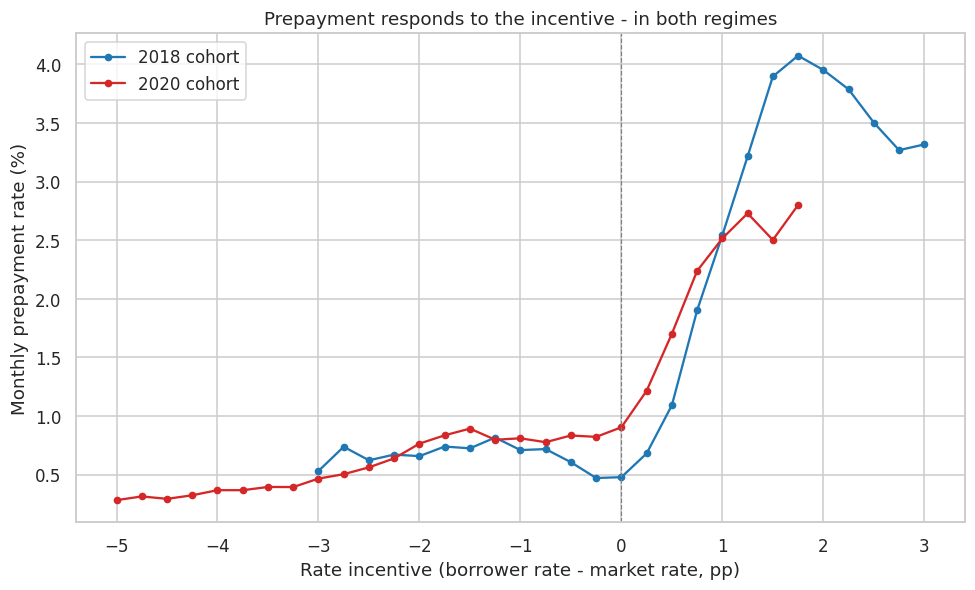

Monthly prepayment rate (%) by incentive bin:
 bin (pp) |    2018 |    2020
    -3.00 |   0.53% |   0.47% |
    -2.00 |   0.66% |   0.76% |
    -1.00 |   0.71% |   0.81% |
    -0.50 |   0.61% |   0.83% |
    +0.00 |   0.48% |   0.90% |
    +0.50 |   1.09% |   1.70% |
    +1.00 |   2.54% |   2.52% |
    +1.50 |   3.90% |   2.50% |
    +2.00 |   3.95% |      -  |
    +2.50 |   3.50% |      -  |


In [154]:
# @title **8.1 - The monthly prepayment rate against the incentive**

# The paper's central question, asked of the raw data: at a given incentive,
# do the two regimes prepay at the same rate? If the curves coincide, the
# incentive-prepayment relationship is stable and a model should transfer;
# where they part, Section 10's transfer test has something to find. I bin
# the incentive in quarter-point steps and compute the share of loan-months
# in each bin that ended in prepayment, per cohort, keeping only bins with
# real mass so no point rests on a handful of rows.

BIN_W    = 0.25
MIN_ROWS = 5_000

fig, ax = plt.subplots(figsize=(9, 5.5))
curves = {}
for v in VINTAGES:
    d = panel[v]
    bins = (d['rate_incentive'] / BIN_W).round() * BIN_W
    g = d.groupby(bins, observed=True)['prepay_event'].agg(['mean', 'size'])
    g = g[g['size'] >= MIN_ROWS]
    curves[v] = g
    ax.plot(g.index, g['mean'] * 100, marker='o', ms=4, color=COL[v],
            label=f'{v} cohort')

ax.axvline(0, color='grey', lw=0.8, ls='--')
ax.set_xlabel('Rate incentive (borrower rate - market rate, pp)')
ax.set_ylabel('Monthly prepayment rate (%)')
ax.set_title('Prepayment responds to the incentive - in both regimes')
ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG}/fig1_hazard_vs_incentive.png', dpi=150)
plt.show()

# The numbers behind the picture, at selected bins, so the figure can be
# quoted precisely in the paper.
print('Monthly prepayment rate (%) by incentive bin:')
print(f'{"bin (pp)":>9} | {"2018":>7} | {"2020":>7}')
for b in [-3.0, -2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0, 2.5]:
    row = f'{b:>+9.2f} |'
    for v in VINTAGES:
        val = curves[v]['mean'].get(b, np.nan) * 100
        row += f' {val:>6.2f}% |' if pd.notna(val) else f' {"-":>6}  |'
    print(row)


This table shows three things:

First, the floor: deep out of the money, both cohorts converge on roughly half a percent a month. At minus three points nobody refinances into a worse rate - that residual is home sales, the other behaviour code 01 captures, and it gives the refinance-versus-sale limitation an empirical size.

Second, the elbow: both curves run flat until the incentive clears about half a point, and then the 2018 rate nearly quadruples between +0.5 and +1.5 (1.09% to 3.90% a month). Refinancing has fixed costs, and half a point is roughly where the savings clear them - the same threshold Section 7 adopted from the literature, now endorsed by the raw data.

Third, the curves do not coincide, they cross. At +0.5 the 2020 cohort prepays more (1.70% against 1.09%); at +1.5 it prepays far less (2.50% against 3.90%). This is composition, not contradiction: the only 2020 loans that ever reached +1.5 were priced well above the market on day one, a selected group, while the 2018 points near zero are dominated by young, freshly originated loans.

2018: S(12)=88.5% | S(24)=61.0% | S(36)=36.7% | S(66)=23.6% | peak hazard 4.36% at age 30
     event-age quartiles: 25% by month 16 | 50% by 24 | 75% by 33
2020: S(12)=85.7% | S(24)=73.4% | S(36)=69.5% | S(66)=61.6% | peak hazard 1.92% at age 11
     event-age quartiles: 25% by month 9 | 50% by 15 | 75% by 27


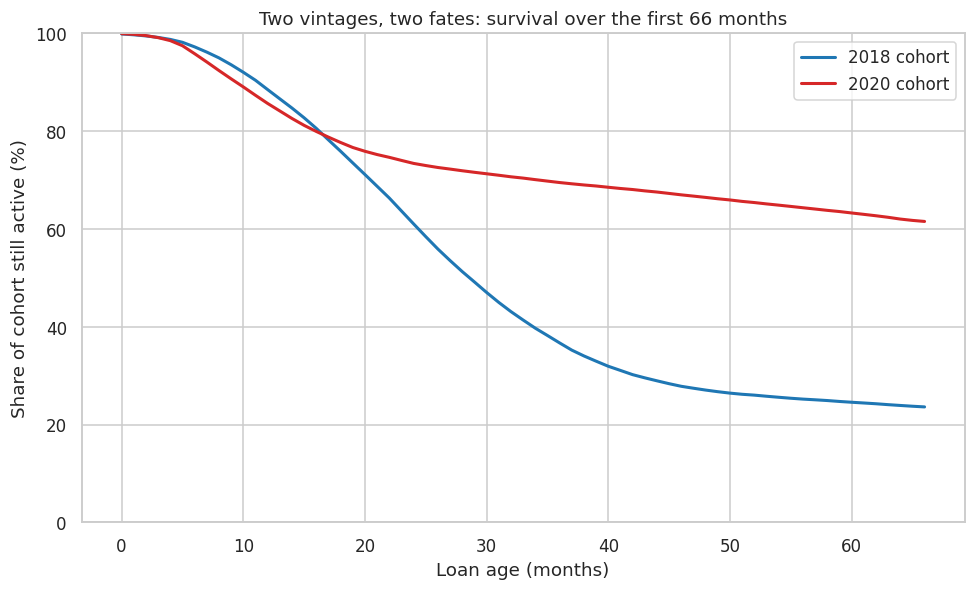

In [155]:
# @title **8.2 - How the two cohorts' lives play out, month by month**

# The discrete-time analogue of a survival curve: at each loan age, the
# hazard is the share of loans then at risk that prepaid that month, and
# survival is the running product of (1 - hazard). The expected values in
# the assert below were computed independently from the raw files, so this
# cell validates the panel's survival arithmetic against an outside read.

EXPECTED_S66 = {2018: 0.236, 2020: 0.616}

fig, ax = plt.subplots(figsize=(9, 5.5))
for v in VINTAGES:
    by_age = panel[v].groupby('loan_age', observed=True)['prepay_event'].agg(['mean', 'size'])
    surv   = (1 - by_age['mean']).cumprod()
    ax.plot(surv.index, surv * 100, color=COL[v], lw=2, label=f'{v} cohort')

    s66  = surv.loc[66.0]
    peak = by_age['mean'].idxmax()
    print(f'{v}: S(12)={surv.loc[12.0]*100:.1f}% | S(24)={surv.loc[24.0]*100:.1f}% | '
          f'S(36)={surv.loc[36.0]*100:.1f}% | S(66)={s66*100:.1f}% | '
          f'peak hazard {by_age["mean"].max()*100:.2f}% at age {peak:.0f}')

    # When the events themselves happened: quartile ages of in-window
    # prepayments - the data's own definition of each cohort's wave, instead
    # of round-number checkpoints.
    ev_ages = panel[v].loc[panel[v]['prepay_event'] == 1, 'loan_age']
    q = ev_ages.quantile([0.25, 0.50, 0.75])
    print(f'     event-age quartiles: 25% by month {q[0.25]:.0f} | '
          f'50% by {q[0.50]:.0f} | 75% by {q[0.75]:.0f}')
    assert abs(s66 - EXPECTED_S66[v]) < 0.005, f'{v}: survival at 66 differs from the independent audit'

ax.set_xlabel('Loan age (months)')
ax.set_ylabel('Share of cohort still active (%)')
ax.set_ylim(0, 100)
ax.set_title('Two vintages, two fates: survival over the first 66 months')
ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG}/fig2_survival_by_age.png', dpi=150)
plt.show()


Reading the curves through the data's own milestones: the 2018 collapse came
early and fast - a quarter of all its in-window prepayments by month 16, half by month 24,three-quarters by month 33 - the months that land in the 2020-21 rate trough. After that the curve flattens and comes to rest at 23.6% still active: the cheap money was gone, and so was most of the cohort.

The 2020 cohort's story is thinner and even earlier, half of its far fewer prepayments happened inside its first 15 months, its only pass through that same trough - and then the curve freezes: 61.6% still active at month 66,
lock-in drawn as a horizontal line. The hazard peaks make the deeper point: 4.36% at age 30 for the 2018 cohort, 1.92% at age 11 for 2020 - different ages, the same calendar window. Prepayment here follows the market's clock, not the loan's.

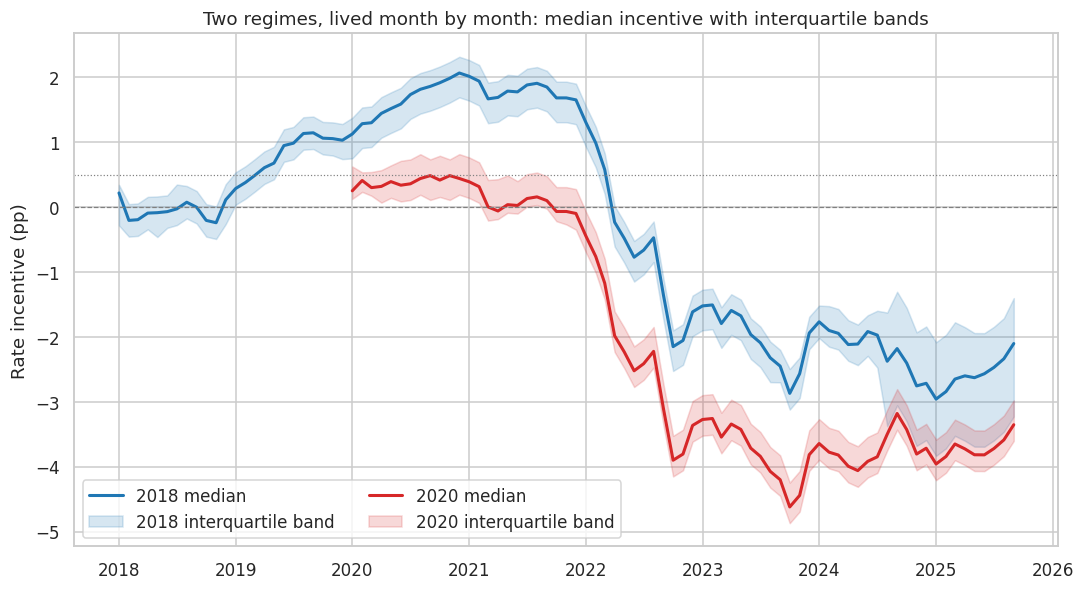

2018 @ 202101: median +2.02 | IQR +1.64 to +2.27 | share above +0.5: 99.9%
2018 @ 202301: median -1.52 | IQR -1.90 to -1.27 | share above +0.5: 0.0%
2018 @ 202506: median -2.57 | IQR -3.69 to -1.94 | share above +0.5: 0.0%
2020 @ 202101: median +0.39 | IQR +0.14 to +0.77 | share above +0.5: 44.1%
2020 @ 202301: median -3.27 | IQR -3.52 to -2.90 | share above +0.5: 0.0%
2020 @ 202506: median -3.82 | IQR -4.07 to -3.44 | share above +0.5: 0.0%


In [156]:
# @title **8.3 - The incentive paths borrowers actually lived, in full distribution**

# The handoff rule for this section: dispersion, not just means. A cohort
# mean of +2 can hide anything, so each cohort gets its median incentive
# over calendar time with an interquartile band around it - the paths the
# middle half of borrowers actually experienced.

fig, ax = plt.subplots(figsize=(10, 5.5))
for v in VINTAGES:
    d = panel[v].copy()
    d['date'] = pd.to_datetime(d['period'], format='%Y%m')
    q = (d.groupby('date')['rate_incentive']
          .quantile([0.25, 0.50, 0.75]).unstack())
    ax.plot(q.index, q[0.50], color=COL[v], lw=2, label=f'{v} median')
    ax.fill_between(q.index, q[0.25], q[0.75], color=COL[v], alpha=0.18,
                    label=f'{v} interquartile band')

ax.axhline(0,   color='grey', lw=0.8, ls='--')
ax.axhline(0.5, color='grey', lw=0.8, ls=':')
ax.set_ylabel('Rate incentive (pp)')
ax.set_title('Two regimes, lived month by month: median incentive with interquartile bands')
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(f'{FIG}/fig3_incentive_paths.png', dpi=150)
plt.show()

# Anchor months in numbers, for the paper. A caution stated once and meant
# everywhere: these describe SURVIVING loans each month - as prepayers exit,
# the pool re-composes, which is visible in the 2018 band after 2021.
for v in VINTAGES:
    d = panel[v]
    for p in [202101, 202301, 202506]:
        s = d.loc[d['period'] == p, 'rate_incentive']
        if len(s):
            print(f'{v} @ {p}: median {s.median():+.2f} | IQR {s.quantile(0.25):+.2f} '
                  f'to {s.quantile(0.75):+.2f} | share above +0.5: {(s > 0.5).mean()*100:.1f}%')


The two cohorts did not just face different incentives - they faced different kinds of chances. In January 2021, at the bottom of the rate trough, 99.9% of surviving 2018 loans sat above the +0.5 threshold (median incentive +2.02); in the same month only 44.1% of the 2020 cohort cleared it (median +0.39). The 2020 cohort's one window was half open, most of those borrowers never had an economically meaningful chance to refinance at any point. By January 2023 the share above threshold is 0.0% for both, and it never recovers. The bands add the dispersion the means conceal: the 2018 interquartile band widens from 0.63 points at the trough to 1.75 by mid-2025, because the refinancing wave removed the homogeneous middle of the cohort and left a mixed remnant, loans whose rates were never far above the market alongside borrowers who sat through the entire trough without acting. Selection, visible as spread.

2018: peak monthly prepayment 5.42% in 2021-03 | rate in 2023-06: 0.79% | final month 2025-09: 0.29%
2020: peak monthly prepayment 1.99% in 2021-03 | rate in 2023-06: 0.50% | final month 2025-09: 0.35%


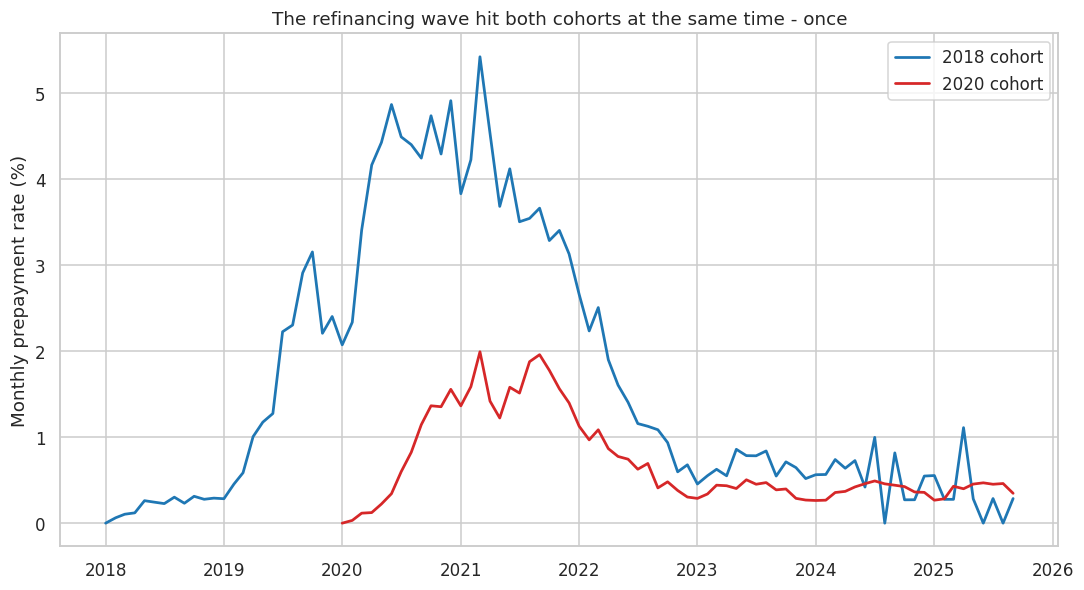

In [157]:
# @title **8.4 - When prepayment actually happened, in calendar time**

# The survival curves showed the cohorts' fates against loan age; this
# figure asks the sharper question - WHEN. If prepayment follows the market
# rather than the loan clock, both cohorts' waves should crest in the same
# calendar months despite their different ages.

fig, ax = plt.subplots(figsize=(10, 5.5))
for v in VINTAGES:
    d = panel[v].copy()
    d['date'] = pd.to_datetime(d['period'], format='%Y%m')
    m = d.groupby('date')['prepay_event'].mean() * 100
    ax.plot(m.index, m, color=COL[v], lw=1.8, label=f'{v} cohort')
    peak = m.idxmax()
    print(f'{v}: peak monthly prepayment {m.max():.2f}% in {peak:%Y-%m} | '
          f'rate in {pd.Timestamp("2023-06-01"):%Y-%m}: {m.get(pd.Timestamp("2023-06-01"), np.nan):.2f}% | '
          f'final month {m.index.max():%Y-%m}: {m.iloc[-1]:.2f}%')

ax.set_ylabel('Monthly prepayment rate (%)')
ax.set_title('The refinancing wave hit both cohorts at the same time - once')
ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG}/fig4_prepayment_calendar.png', dpi=150)
plt.show()


Loan age disappears from this picture, and what remains is the market. Both cohorts' prepayment waves peak in the same month - March 2021, at 5.42% of surviving 2018 loans and 1.99% of surviving 2020 loans, despite the cohorts
being at entirely different points in their lives. The 2018 cohort in fact answered every window it was offered: a first, smaller wave when rates dipped in late 2019, then the great one through 2020-21. After mid-2022 the door closes for both, and by the end the curves converge at the home-sale floor and quietly cross - 0.29% for 2018 against 0.35% for 2020 in September 2025, the most selected survivors in the data now the marginally slower group. One wave, shared in calendar time, never repeated: that is the regime story in a single figure.

In [158]:
# @title **8.5 - Who the borrowers were: the loan-characteristics table**

# The paper's data section needs one table describing each cohort at
# origination. The origination features repeat on every monthly row, so I
# collapse to one row per loan first - otherwise long-lived loans would be
# overweighted and the table would describe loan-months, not loans.

rows = []
for v in VINTAGES:
    loans = panel[v].drop_duplicates('loan_sequence_number')
    rows.append({
        'vintage':               v,
        'loans':                 len(loans),
        'credit score (median)': loans['credit_score'].median(),
        'orig LTV (median)':     loans['orig_ltv'].median(),
        'orig DTI (median)':     loans['orig_dti'].median(),
        'orig UPB $k (median)':  loans['orig_upb'].median() / 1_000,
        'SATO pp (mean)':        loans['sato'].mean(),
        '30-year share %':       (loans['orig_loan_term'] == 360).mean() * 100,
        'purchase %':            (loans['loan_purpose'] == 'P').mean() * 100,
        'cash-out refi %':       (loans['loan_purpose'] == 'C').mean() * 100,
        'owner-occupied %':      (loans['occupancy_status'] == 'P').mean() * 100,
    })
table1 = pd.DataFrame(rows).set_index('vintage').T.round(2)
print(table1.to_string())

TAB = f'{OUT}/tables'
os.makedirs(TAB, exist_ok=True)
table1.to_csv(f'{TAB}/table1_loan_characteristics.csv')
print(f'\nSaved -> {TAB}/table1_loan_characteristics.csv')


vintage                      2018        2020
loans                 49,770.0000 49,857.0000
credit score (median)    754.0000    768.0000
orig LTV (median)         80.0000     74.0000
orig DTI (median)         37.0000     34.0000
orig UPB $k (median)     207.0000    263.0000
SATO pp (mean)             0.1500      0.2200
30-year share %           84.0800     72.9100
purchase %                66.8400     29.9800
cash-out refi %           20.8700     19.2900
owner-occupied %          87.3300     91.6800

Saved -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/tables/table1_loan_characteristics.csv


### Section 8 - What the raw data shows before any model

Four figures and a table establish the paper's empirical foundations.

#### The response to the incentive has a floor, an elbow, and a crossing

Deep out of the money, both cohorts prepay at roughly half a percent per month, a baseline of home sales unrelated to refinancing. The response to the incentive begins at approximately +0.5 percentage points, consistent
with the fixed costs of refinancing, and rises steeply: the 2018 rate increases from 1.09% to 3.90% per month between +0.5 and +1.5. The two
cohorts' curves do not coincide, the 2020 cohort prepays more at +0.5 and substantially less at +1.5, indicating that the incentive-response relationship is entangled with the composition of the borrowers experiencing it.

#### The cohorts' outcomes diverged early and permanently

A quarter of the 2018 cohort's in-window prepayments occurred by month 16, half by month 24, and three quarters by month 33; the cohort stabilises at 23.6% still active. The 2020 cohort recorded half of its far fewer prepayments within its first 15 months and stabilises at 61.6% still active.

#### The refinancing wave was shared in calendar time and unequally available

Both cohorts' monthly prepayment rates peak in March 2021 - 5.42% and 1.99% of surviving loans - at loan ages of roughly 30 and 11 months respectively: timing followed market conditions, not loan age. The opportunity was unequal: at the trough, 99.9% of surviving 2018 loans stood above the +0.5 threshold against 44.1% of 2020 loans. Dispersion also shifted with selection, the 2018 interquartile band widens from 0.63 to 1.75 percentage points as the refinancing wave removed the most responsive borrowers.

#### The cohorts differ in composition, not only in regime

The 2020 cohort shows a higher median credit score (768 against 754), lower original LTV (74 against 80) and DTI (34 against 37), larger median balance (263k against 207k), and a 70% refinance share against 67% purchase loans in 2018. Regime and composition are therefore entangled in every raw comparison above;separating them, holding borrower characteristics
constant while the regime varies, is the task of the models that follow.

# **Section 9 - Modelling: Logistic Baseline and Gradient Boosting**

Two models, each fitted separately to each cohort, so that Section 10 can ask its question: does a model calibrated in one regime work in the other? The logit comes first because its coefficients, standard errors, and p-values
make the economics inspectable; the gradient-boosting model follows because the raw patterns in Section 8, the elbow, the floor, are exactly the non-linearities a linear model cannot bend around. Four decisions shape everything here.

**Decision 1 - the split is by loan, never by row.** A loan's months are deeply correlated; scattering them across train and test would let the model partially memorise its own test set and report flattering numbers. I hold out 20% of *loans* per cohort, so every test month belongs to a loan the model has never seen.

**Decision 2 - one feature list, one forced exception.** The incentive and its path (burnout, peak, streak), the constraints(start-of-month equity, delinquency, assistance), the borrower at origination (credit score, DTI, LTV, log loan size, term, purpose, occupancy, SATO), plus loan age and calendar month. Deliberately excluded: the market rate and the loan's own rate, the incentive is their difference, and all three together would make
the logit unidentifiable, and start-of-month balance, already carried by loan size, age, and term. The exception: the two impairment flags
(delinquency, assistance) appear only in the boosting model, because in this data they perfectly predict non-prepayment and no finite logit coefficient exists for a perfect predictor, the numbers and the full reasoning are in 9.2.

**Decision 3 - gaps are filled in, and the fill is part of the model.** The logit refuses rows with missing values. Gaps live in two places:
start-of-month ELTV (absent in a loan's first months, before Freddie Mac produces its first estimate) and a few origination fields (under 1% of loans). Each gap is filled with the column's median - computed from the training loans only, and carried by the fitted model wherever it later
predicts, including on the other cohort: fill values are learned numbers, part of the model just as coefficients are. ELTV also gets a 0/1 flag marking filled rows, because its gaps are not random - they mark a loan's earliest months, which behave differently - and the flag lets the model see "this was filled in" rather than mistaking those rows for typical ones.

**Decision 4 - the rarity of the event is respected, not corrected.** Only about two rows in a hundred (2018) and fewer than one in a hundred (2020) are prepayment months. The standard recipe for rare events - rebalancing the
data until the model trains on something closer to fifty-fifty - would teach it that prepayment is common and inflate every probability it produces. This project cannot afford that: the monthly probability itself is the quantity of interest, and Section 10 compares those probabilities across regimes. With 38,000 events in one cohort and 18,000 in the other, rarity is not a problem to fix, it is the fact being measured.

In [159]:
# @title **9.1 - Design matrices and the loan-level split**

# One function turns a panel into a model-ready matrix, so that every model
# in this project, whatever cohort it trains or predicts on, sees features
# built by exactly the same rules. Medians are learned from training data
# and passed back in wherever that model predicts.

FEAT_CONT = ['rate_incentive', 'burnout', 'incentive_peak', 'itm_streak',
             'loan_age', 'eltv_start', 'dq_months', 'in_assistance',
             'credit_score', 'orig_dti', 'orig_ltv', 'sato']
FEAT_CAT  = ['loan_purpose', 'occupancy_status', 'cal_month']

def make_design(df, medians=None):
    X = df[FEAT_CONT].copy()
    X['log_orig_upb'] = np.log(df['orig_upb'])
    X['is_30yr']      = (df['orig_loan_term'] == 360).astype('int8')
    X['eltv_missing'] = X['eltv_start'].isna().astype('int8')

    if medians is None:
        medians = X[['eltv_start', 'credit_score', 'orig_dti', 'orig_ltv']].median()
    X = X.fillna(medians)

    d = pd.get_dummies(df[FEAT_CAT].astype({'cal_month': 'category'}),
                       drop_first=True, dtype='int8')
    X = pd.concat([X, d], axis=1).astype('float64')
    return X, df['prepay_event'].astype('int8'), medians

# The split: 20% of LOANS held out per cohort, fixed seed. Rows of the same
# loan can never straddle the boundary.
split = {}
for v in VINTAGES:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
    idx_tr, idx_te = next(gss.split(panel[v], groups=panel[v]['loan_sequence_number']))
    tr, te = panel[v].iloc[idx_tr], panel[v].iloc[idx_te]

    overlap = set(tr['loan_sequence_number']) & set(te['loan_sequence_number'])
    assert not overlap, f'{v}: loans leak across the split'
    split[v] = {'train': tr, 'test': te}

    print(f'{v}: train {tr["loan_sequence_number"].nunique():>6,} loans '
          f'({len(tr):>9,} rows, event rate {tr["prepay_event"].mean()*100:.2f}%) | '
          f'test {te["loan_sequence_number"].nunique():>6,} loans '
          f'({len(te):>9,} rows, event rate {te["prepay_event"].mean()*100:.2f}%)')


2018: train 39,816 loans (1,427,229 rows, event rate 2.13%) | test  9,954 loans (  351,085 rows, event rate 2.21%)
2020: train 39,885 loans (1,866,264 rows, event rate 0.79%) | test  9,972 loans (  470,084 rows, event rate 0.77%)


In [160]:
# @title **9.2 - The logistic baseline: inspectable economics**

# Fitting this model produced a statistical finding, not a bug: the first attempt refused
# to converge because the impairment features perfectly predict non-prepayment - zero
# prepayments across all 38,084 assistance-plan months of the two cohorts combined, and
# zero across every delinquent 2020 month. Perfect prediction (separation) sends a logit
# coefficient to negative infinity, so no finite estimate exists. The phenomenon is real
# forbearance and delinquency do not merely dampen refinancing here, they extinguish it
# but a logit cannot print an infinite effect in a coefficient table. Both features
# therefore remain in the gradient-boosting model, which expresses "never" without
# difficulty, and leave the logit. With them gone, Newton's method, whose use of curvature
# makes it indifferent to the features' very different scales, converges normally. Standard
# errors are clustered at the loan level: a loan's months are not independent, and classical
# errors would overstate precision. Clustering changes only the standard errors and p-values,
# coefficients and predictions are identical. The asserts check results, not just the
# optimiser's self-report: a fit is accepted only if the incentive coefficient is positive
# and the holdout AUC is far above chance.

LOGIT_DROP = ['in_assistance', 'dq_months']

logit_fit, logit_med = {}, {}
for v in VINTAGES:
    X_tr, y_tr, med = make_design(split[v]['train'])
    logit_med[v] = med
    m = sm.Logit(y_tr, sm.add_constant(X_tr.drop(columns=LOGIT_DROP))
                 ).fit(disp=0, maxiter=100, cov_type='cluster',
                       cov_kwds={'groups': pd.factorize(split[v]['train']['loan_sequence_number'])[0]})
    logit_fit[v] = m

    X_te, y_te, _ = make_design(split[v]['test'], medians=med)
    auc = roc_auc_score(y_te, m.predict(sm.add_constant(X_te.drop(columns=LOGIT_DROP))))

    assert m.mle_retvals['converged'],      f'{v}: logit did not converge'
    assert m.params['rate_incentive'] > 0,  f'{v}: incentive coefficient not positive - fit is not credible'
    assert auc > 0.65,                      f'{v}: holdout AUC {auc:.3f} - model did not actually train'

    show = ['rate_incentive', 'burnout', 'itm_streak', 'eltv_start',
            'credit_score', 'sato', 'log_orig_upb', 'orig_dti']
    print(f'\n{v} logit - holdout AUC {auc:.3f} | key coefficients:')
    print(f'{"variable":<16} {"coef":>9} {"std err":>9} {"p-value":>9}')
    for c in show:
        print(f'{c:<16} {m.params[c]:>+9.4f} {m.bse[c]:>9.4f} {m.pvalues[c]:>9.3g}')



2018 logit - holdout AUC 0.740 | key coefficients:
variable              coef   std err   p-value
rate_incentive     +0.4831    0.0185 1.39e-149
burnout            -0.0226    0.0010 3.55e-116
itm_streak         -0.0044    0.0016    0.0052
eltv_start         -0.0020    0.0008   0.00925
credit_score       +0.0036    0.0001 9.78e-134
sato               -0.5888    0.0288  5.22e-93
log_orig_upb       +0.7285    0.0126         0
orig_dti           -0.0055    0.0007  1.59e-16

2020 logit - holdout AUC 0.706 | key coefficients:
variable              coef   std err   p-value
rate_incentive     +0.3538    0.0129  2.2e-165
burnout            -0.0251    0.0021   1.9e-32
itm_streak         +0.0194    0.0022  4.43e-19
eltv_start         -0.0202    0.0012  1.08e-65
credit_score       -0.0000    0.0002     0.873
sato               -1.3881    0.0515  6.1e-160
log_orig_upb       +0.4741    0.0182 1.14e-149
orig_dti           +0.0005    0.0009     0.604


In [161]:
# @title **9.3 - Gradient boosting: the model that can bend**

# HistGradientBoostingClassifier on the identical design matrix, one per
# cohort. Defaults are deliberately kept (with the project seed): this
# paper's contribution is the transfer test, not a tuning exercise, and
# defaults make the comparison between cohorts clean. Alongside AUC I report
# average precision, which is the harder metric at a 1-2% event rate.

hgb_fit = {}
for v in VINTAGES:
    X_tr, y_tr, _ = make_design(split[v]['train'], medians=logit_med[v])
    hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
    hgb.fit(X_tr, y_tr)
    hgb_fit[v] = hgb

    X_te, y_te, _ = make_design(split[v]['test'], medians=logit_med[v])
    p = hgb.predict_proba(X_te)[:, 1]
    print(f'{v} HistGB - holdout AUC {roc_auc_score(y_te, p):.3f} | '
          f'average precision {average_precision_score(y_te, p):.3f} '
          f'(event-rate baseline {y_te.mean():.3f}) | '
          f'iterations used: {hgb.n_iter_}')


2018 HistGB - holdout AUC 0.767 | average precision 0.062 (event-rate baseline 0.022) | iterations used: 77
2020 HistGB - holdout AUC 0.755 | average precision 0.031 (event-rate baseline 0.008) | iterations used: 55


In [162]:
# @title **9.4 - Checkpoint the fitted models and the split**

# Sections 10 and 11 evaluate and interpret these exact objects, so the
# fitted models, their imputation medians, and the identity of the held-out
# loans all go to Drive together - the split must be reloadable, not merely
# reproducible.

MODELS = f'{OUT}/models'
os.makedirs(MODELS, exist_ok=True)
for v in VINTAGES:
    joblib.dump({'logit': logit_fit[v], 'hgb': hgb_fit[v],
                 'medians': logit_med[v],
                 'test_loans': split[v]['test']['loan_sequence_number'].unique()},
                f'{MODELS}/models_{v}.joblib')
    print(f'{v}: saved logit + HistGB + medians + test-loan list -> {MODELS}/models_{v}.joblib')


2018: saved logit + HistGB + medians + test-loan list -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/models/models_2018.joblib
2020: saved logit + HistGB + medians + test-loan list -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/models/models_2020.joblib


### Section 9 - What the models learned

Each cohort has two fitted models - a logistic baseline and a gradient-boosted tree model - trained on 80% of its loans (39,816 and 39,885) and evaluated on the held-out 20% (9,954 and 9,972 loans; 351,085 and 470,084 loan-months). Splitting is by loan, so no loan's months appear
on both sides. Event rates are left at their natural levels (2.13% and 0.79% of training months), since calibrated monthly probabilities are the quantity of interest.

#### Estimation produced a finding

The logit initially failed to converge because the impairment features perfectly predict non-prepayment: no prepayment occurs in any of the 38,084 assistance-plan months of the two cohorts combined, nor in any delinquent 2020 month (delinquent 2018 months record 22 events in 46,186). A finite logit coefficient does not exist for a perfect predictor, so the two flags
are retained only in the tree model, which accommodates them without difficulty. Substantively: forbearance and delinquency do not reduce refinancing in this data - they eliminate it.

#### The coefficients agree on mechanics and disagree on magnitudes

Both cohorts' estimates carry the expected signs at conventional significance, with regime-dependent magnitudes. The incentive coefficient is +0.48 per percentage point in 2018 against +0.35 in 2020. Burnout is nearly identical across regimes (-0.023 and -0.025). SATO is negative in both and substantially stronger in 2020 (-0.59 against -1.39), consistent with unobserved frictions among borrowers priced above the market at origination. Credit score is highly significant in 2018 (+0.0036) and indistinguishable from zero in 2020 (p = 0.87) - a compositional result:
the 2020 cohort consists of pre-selected prime refinancers with little remaining score variation. Loan size carries the largest effect in both cohorts (+0.73 and +0.47 per log unit), and current equity binds an order of magnitude harder in 2020 (-0.020 against -0.002).

#### The tree models outperform where the raw data is nonlinear

Holdout AUCs are 0.767 and 0.755 against the logits' 0.740 and 0.706, with average precision of 0.062 and 0.031, roughly three and four times the event-rate baselines. The larger gain accrues to the 2018 cohort, consistent with the floor and elbow of Section 8.1.

#### Interpretation of the performance level

Discrimination in the mid-0.70s reflects the information content of a loan file: the timing of a borrower's action depends substantially on
circumstances recorded in no field of this data, and a linear specification already attains 0.74. The models' role in what follows is not maximal ranking but honestly calibrated monthly probabilities, estimated on each regime in isolation. Fitted models, imputation medians, and held-out loan identities are checkpointed together.

# **Section 10 - Evaluation and the Cross-Regime Transfer Test**

Everything so far built two sealed boxes: a 2018 model and a 2020 model, each trained entirely inside its own rate regime. This section opens each box over the other regime and measures what survives, the situation of any frozen production model that was calibrated in one rate environment and is still running when the environment flips.

Three design points.

First, every evaluation uses the same held-out test sets: each model scores its own cohort's test loans (which must reproduce Section 9's numbers exactly, a built-in validation) and the other cohort's test loans, which are doubly out of sample: unseen loans from an unseen regime.

Second, the boxes stay sealed - each model prepares whatever data it scores using its own training medians, exactly as a deployed model would.

Third, transfer has two dimensions and they can fail independently: *ranking* (does the model still order risky above safe - measured by AUC,
here in 10.1) and *levels* (are the predicted monthly probabilities still honest - measured by calibration in 10.2, and the dimension MBS pricing actually runs on).

One asymmetry is predictable in advance and on record: no 2020 training loan ever experienced an incentive much above +1.5, so the 2020 model scoring 2018 loans must extrapolate into territory it has never seen, while the 2018 model scoring 2020 loans mostly interpolates. The test gets to confirm or embarrass that prediction.

In [163]:
# @title **10.1 - The transfer matrix: every model scores every regime**

# Four evaluations per model family. The diagonal (model on its own cohort's
# test set) must reproduce Section 9 exactly - the asserts enforce it. The
# off-diagonal is the experiment. One technical safeguard: the test matrix
# is aligned to the exact columns each model was fitted on, so a category
# absent from one cohort's test set could never silently shift the features.

EXPECTED_DIAG = {('logit', 2018): 0.740, ('logit', 2020): 0.706,
                 ('hgb',   2018): 0.767, ('hgb',   2020): 0.755}

results = []
for family in ['logit', 'hgb']:
    print(f'\n{family.upper()} - AUC matrix (rows: training cohort, columns: evaluation cohort):')
    print(f'{"":>12} {"on 2018":>9} {"on 2020":>9}')
    for train_v in VINTAGES:
        line = f'{f"model {train_v}":>12}'
        for eval_v in VINTAGES:
            X_raw, y, _ = make_design(split[eval_v]['test'], medians=logit_med[train_v])
            if family == 'logit':
                cols = logit_fit[train_v].params.index
                X = sm.add_constant(X_raw.drop(columns=LOGIT_DROP)).reindex(columns=cols, fill_value=0)
                p = logit_fit[train_v].predict(X)
            else:
                cols = hgb_fit[train_v].feature_names_in_
                X = X_raw.reindex(columns=cols, fill_value=0)
                p = np.asarray(hgb_fit[train_v].predict_proba(X)[:, 1])
            auc = roc_auc_score(y, p)
            results.append({'family': family, 'train': train_v, 'eval': eval_v, 'auc': auc,
                            'pred_mean': float(np.mean(p)), 'actual': float(y.mean())})
            if train_v == eval_v:
                assert round(auc, 3) == EXPECTED_DIAG[(family, train_v)], \
                    f'{family} {train_v}: diagonal does not reproduce Section 9'
            line += f' {auc:>9.3f}'
        print(line)

res = pd.DataFrame(results)

print('\nTransfer gaps (native AUC minus foreign-model AUC, on the same test set):')
for family in ['logit', 'hgb']:
    for ev in VINTAGES:
        within = res.query('family == @family and train == @ev and eval == @ev')['auc'].iloc[0]
        cross  = res.query('family == @family and train != @ev and eval == @ev')['auc'].iloc[0]
        tr = [v for v in VINTAGES if v != ev][0]
        print(f'   {family:>5}: model {tr} on the {ev} test set: {cross:.3f} '
              f'against native {within:.3f} -> gap {within - cross:+.3f}')



LOGIT - AUC matrix (rows: training cohort, columns: evaluation cohort):
               on 2018   on 2020
  model 2018     0.740     0.689
  model 2020     0.711     0.706

HGB - AUC matrix (rows: training cohort, columns: evaluation cohort):
               on 2018   on 2020
  model 2018     0.767     0.719
  model 2020     0.745     0.755

Transfer gaps (native AUC minus foreign-model AUC, on the same test set):
   logit: model 2020 on the 2018 test set: 0.711 against native 0.740 -> gap +0.029
   logit: model 2018 on the 2020 test set: 0.689 against native 0.706 -> gap +0.018
     hgb: model 2020 on the 2018 test set: 0.745 against native 0.767 -> gap +0.023
     hgb: model 2018 on the 2020 test set: 0.719 against native 0.755 -> gap +0.037


Mean predicted monthly hazard against actual (the levels test):
 family   model  test set  predicted   actual   ratio
  logit    2018      2018      2.13%    2.21%   0.96x  native
  logit    2018      2020      0.48%    0.77%   0.62x  CROSS
  logit    2020      2018      7.03%    2.21%   3.18x  CROSS
  logit    2020      2020      0.79%    0.77%   1.03x  native
    hgb    2018      2018      2.16%    2.21%   0.98x  native
    hgb    2018      2020      0.79%    0.77%   1.03x  CROSS
    hgb    2020      2018      2.85%    2.21%   1.29x  CROSS
    hgb    2020      2020      0.83%    0.77%   1.08x  native


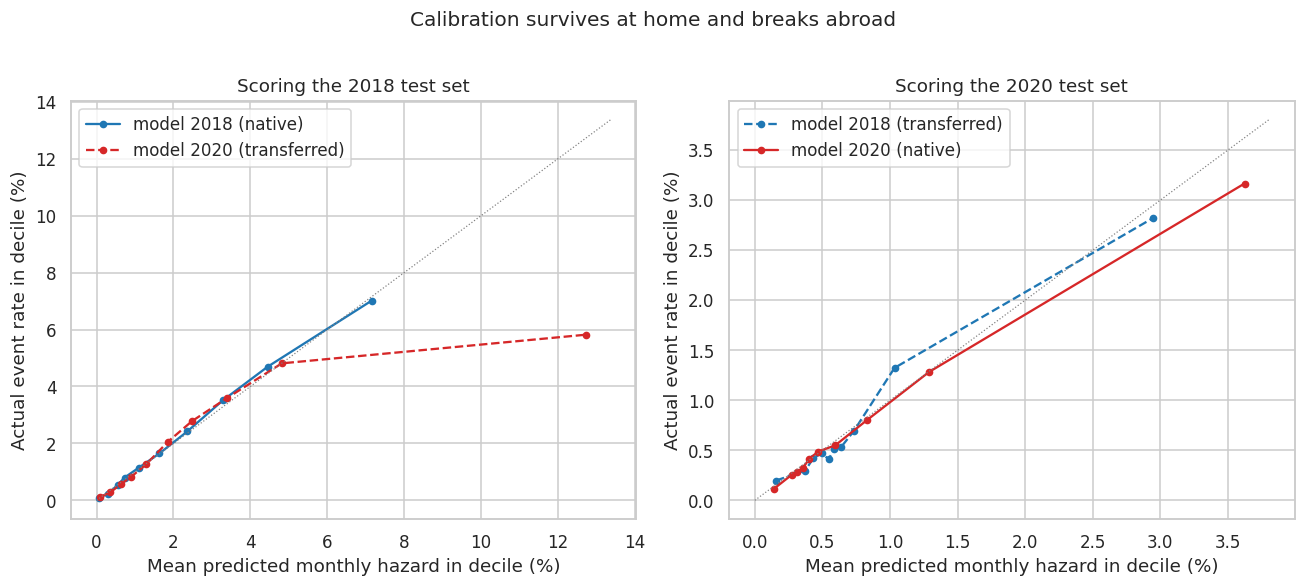

In [164]:
# @title **10.2 - Calibration: do the levels survive the regime change?**

# AUC asks whether a model still orders risky above safe. Pricing asks a
# harder question: are the predicted monthly probabilities still TRUE? A
# model can rank almost perfectly and be wrong about every level - and
# levels are what MBS valuation and servicing economics run on. Two
# measures: the ratio of mean predicted hazard to the actual event rate
# (the bias a portfolio inherits wholesale), and decile calibration curves
# (where in the risk spectrum the bias lives). The scoring helper mirrors
# 10.1's column alignment exactly - sealed boxes, own medians.

def score(family, train_v, eval_v):
    X_raw, y, _ = make_design(split[eval_v]['test'], medians=logit_med[train_v])
    if family == 'logit':
        cols = logit_fit[train_v].params.index
        X = sm.add_constant(X_raw.drop(columns=LOGIT_DROP)).reindex(columns=cols, fill_value=0)
        return np.asarray(logit_fit[train_v].predict(X)), y
    cols = hgb_fit[train_v].feature_names_in_
    X = X_raw.reindex(columns=cols, fill_value=0)
    return np.asarray(hgb_fit[train_v].predict_proba(X)[:, 1]), y

print('Mean predicted monthly hazard against actual (the levels test):')
print(f'{"family":>7} {"model":>7} {"test set":>9} {"predicted":>10} {"actual":>8} {"ratio":>7}')
for family in ['logit', 'hgb']:
    for train_v in VINTAGES:
        for eval_v in VINTAGES:
            p, y = score(family, train_v, eval_v)
            tag = 'native' if train_v == eval_v else 'CROSS'
            print(f'{family:>7} {train_v:>7} {eval_v:>9} {p.mean()*100:>9.2f}% '
                  f'{y.mean()*100:>7.2f}% {p.mean()/y.mean():>6.2f}x  {tag}')

# Decile calibration for the boosting models: points on the diagonal mean
# "predicted X%, observed X%". Native models solid, transferred dashed.
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, ev in zip(axes, VINTAGES):
    top = 0
    for train_v in VINTAGES:
        p, y = score('hgb', train_v, ev)
        g = (pd.DataFrame({'p': p, 'y': y})
               .groupby(pd.qcut(p, 10, duplicates='drop'), observed=True).mean())
        style = '-' if train_v == ev else '--'
        ax.plot(g['p'] * 100, g['y'] * 100, style, marker='o', ms=4, color=COL[train_v],
                label=f'model {train_v}' + (' (native)' if train_v == ev else ' (transferred)'))
        top = max(top, g['p'].max() * 100, g['y'].max() * 100)
    ax.plot([0, top * 1.05], [0, top * 1.05], color='grey', lw=0.8, ls=':')
    ax.set_xlabel('Mean predicted monthly hazard in decile (%)')
    ax.set_ylabel('Actual event rate in decile (%)')
    ax.set_title(f'Scoring the {ev} test set')
    ax.legend()
fig.suptitle('Calibration survives at home and breaks abroad', y=1.02)
fig.tight_layout()
fig.savefig(f'{FIG}/fig5_calibration.png', dpi=150, bbox_inches='tight')
plt.show()


In [165]:
# @title **10.3 - Save the transfer exhibit**

# The paper's central table: for every model family and direction, the
# ranking metric (AUC) and the levels metric (predicted-to-actual ratio)
# side by side. Assembled from the evaluations above and saved with the
# other paper tables.

rows = []
for family in ['logit', 'hgb']:
    for train_v in VINTAGES:
        for eval_v in VINTAGES:
            auc = res.query('family == @family and train == @train_v and eval == @eval_v')['auc'].iloc[0]
            p, y = score(family, train_v, eval_v)
            rows.append({'family': family, 'model': train_v, 'test set': eval_v,
                         'direction': 'native' if train_v == eval_v else 'cross',
                         'AUC': round(auc, 3),
                         'pred/actual': round(float(p.mean() / y.mean()), 2)})
table2 = pd.DataFrame(rows)
print(table2.to_string(index=False))
table2.to_csv(f'{TAB}/table2_transfer_test.csv', index=False)
print(f'\nSaved -> {TAB}/table2_transfer_test.csv')


family  model  test set direction    AUC  pred/actual
 logit   2018      2018    native 0.7400       0.9600
 logit   2018      2020     cross 0.6890       0.6200
 logit   2020      2018     cross 0.7110       3.1800
 logit   2020      2020    native 0.7060       1.0300
   hgb   2018      2018    native 0.7670       0.9800
   hgb   2018      2020     cross 0.7190       1.0300
   hgb   2020      2018     cross 0.7450       1.2900
   hgb   2020      2020    native 0.7550       1.0800

Saved -> /content/drive/MyDrive/MSBA/Summer Semester/BA889/Output/tables/table2_transfer_test.csv


### Section 10 - What survived the regime change

Each model scored its own regime's held-out loans and the other regime's, unseen loans from an unseen regime, prepared with the model's own training medians, as a frozen production model would score them. The native evaluations reproduce Section 9 exactly, confirming the machinery before the experiment. The two dimensions of transfer separate, and that
separation is the paper's central result.

#### Ranking survives

Every cross-regime AUC lies within 0.02-0.04 of its native benchmark (worst case 0.689 against 0.706): a model from the opposite regime still orders risky months above safe ones nearly as well as the home model. On the metric a standard validation report leads with, these models transfer.

#### Calibration does not - and the failure is asymmetric

Native models are honest (predicted-to-actual ratios of 0.96 to 1.08). Transferred models are not: the 2018 logit predicts 0.62 times the true
hazard on 2020 data, while the 2020 logit predicts 3.18 times on 2018 data. The direction matters: models calibrated in the low-activity regime and deployed into the refinancing wave overpredict severely, because they extrapolate a steep learned response into incentive territory they never observed; the reverse direction underpredicts, because the 2018 model never learned the home-sale floor that supports prepayment when refinancing is uneconomical. The tree model is more robust but not immune: 1.03 in one direction, 1.29 in the other, with its highest-risk decile of the 2018 test set predicted at 12.7% against 5.8% observed.

#### What this means

A model carried across regimes can still identify WHICH loans are riskier, but it can no longer state HOW MUCH prepayment there will be, and it is wrong by as much as a factor of three. These are different abilities, and the standard
validation metric tests only the first. A bank checking a transferred model's AUC would conclude it still works; a portfolio priced on its predicted levels would be systematically mispriced. That gap, between the metric that gets reported and the quantity that gets priced, is this project's central finding.

# **Section 11 - Interpretation: Why the Models Fail Where They Do**

Section 10 measured the damage; this section locates it. Two tools, both applied to the boosting models, which carried the transfer test. Permutation importance asks which variables each model actually leans on, shuffle one column and see how much performance falls, so the two regimes' models can be compared as decision-makers, not just as scorers. Partial dependence then traces each model's learned hazard-versus-incentive curve, with each model's
training range marked on the axis: if the 2020 model's curve goes flat exactly where its training data ran out, the 3.18x and 1.29x overpredictions of Section 10 have their mechanism, a model asked about territory it has never seen answers with the last thing it learned.

Top-10 AUC drop when shuffled (each model on its own test set):
                 2018   2020
rate_incentive 0.0210 0.1622
loan_age       0.0358 0.0515
log_orig_upb   0.0488 0.0174
itm_streak     0.0484 0.0023
eltv_start     0.0124 0.0184
burnout        0.0162 0.0120
dq_months      0.0178 0.0059
incentive_peak 0.0045 0.0063
in_assistance  0.0086 0.0010
sato           0.0047 0.0048


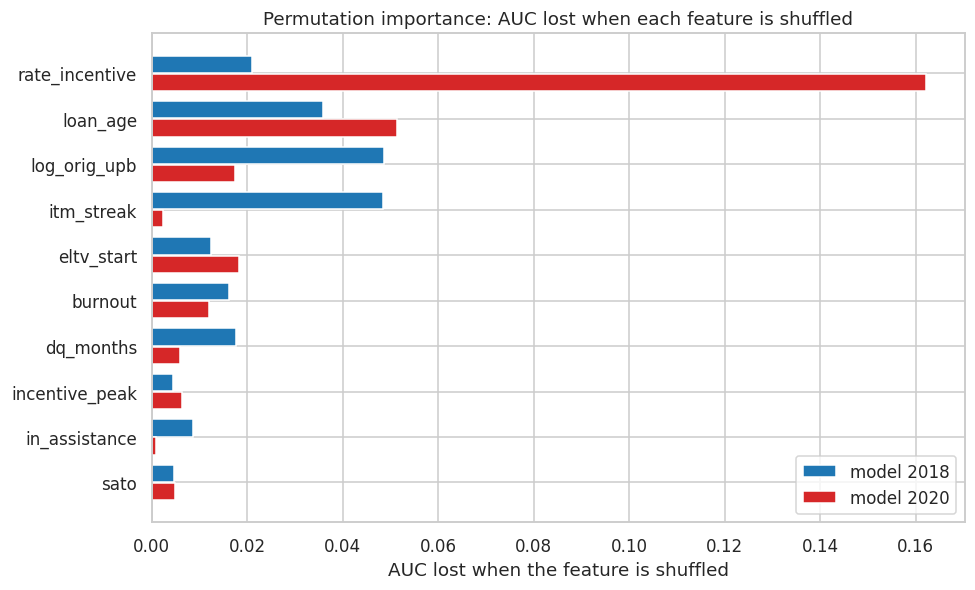

In [166]:
# @title **11.1 - What each model actually leans on**

# Permutation importance on each boosting model, over its own cohort's test
# set: shuffle one feature, measure the AUC drop, repeat five times for
# stability. Expensive but honest - importance measured on held-out data,
# in the model's own regime.

imp = {}
for v in VINTAGES:
    X, y, _ = make_design(split[v]['test'], medians=logit_med[v])
    X = X.reindex(columns=hgb_fit[v].feature_names_in_, fill_value=0)
    r = permutation_importance(hgb_fit[v], X, y, scoring='roc_auc',
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    imp[v] = pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False)

top = pd.DataFrame({v: imp[v].head(10) for v in VINTAGES})
print('Top-10 AUC drop when shuffled (each model on its own test set):')
comb = (pd.DataFrame({v: imp[v] for v in VINTAGES})
          .assign(total=lambda d: d.sum(axis=1))
          .sort_values('total', ascending=False).drop(columns='total').head(10))
print(comb.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 5.5))
yy = np.arange(len(comb))
ax.barh(yy - 0.2, comb[2018], height=0.38, color=COL[2018], label='model 2018')
ax.barh(yy + 0.2, comb[2020], height=0.38, color=COL[2020], label='model 2020')
ax.set_yticks(yy, comb.index)
ax.invert_yaxis()
ax.set_xlabel('AUC lost when the feature is shuffled')
ax.set_title('Permutation importance: AUC lost when each feature is shuffled')
ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG}/fig6_importance.png', dpi=150)
plt.show()


The rate incentive (`rate_incentive`) is the dominant variable of the 2020 model - 0.162 of AUC lost when shuffled, more than all other features combined - and a modest contributor to the 2018 model (0.021). The reason lies in what ranking requires within each regime. In the lock-in cohort, prepayment concentrates in the single early window when refinancing was
economical, so whether that window was open performs nearly all of the ranking work. In the 2018 cohort the window stood open for years - 60% of loan-months were in the money - so discrimination depends on which borrowers act on an open opportunity, and when: loan size(`log_orig_upb`, 0.049), position within the in-the-money streak (`itm_streak`, 0.048 against 0.002 for the 2020 model), loan age (`loan_age`), and the impairment flags (`dq_months`, `in_assistance`), which carry several times more weight in 2018 because the inability to refinance only distinguishes a borrower when refinancing is otherwise widespread. The two regimes produced not merely different parameter values but different decision structures: the 2020 model depends on a single variable, while the 2018 model distributes its reliance across several.

model 2018: training incentive runs to +2.93 (99.5th pct) | learned hazard at 0: 1.37% | at +1: 1.71% | at +2: 2.01% | at +2.5: 2.10%
model 2020: training incentive runs to +1.79 (99.5th pct) | learned hazard at 0: 1.53% | at +1: 3.21% | at +2: 3.57% | at +2.5: 3.57%


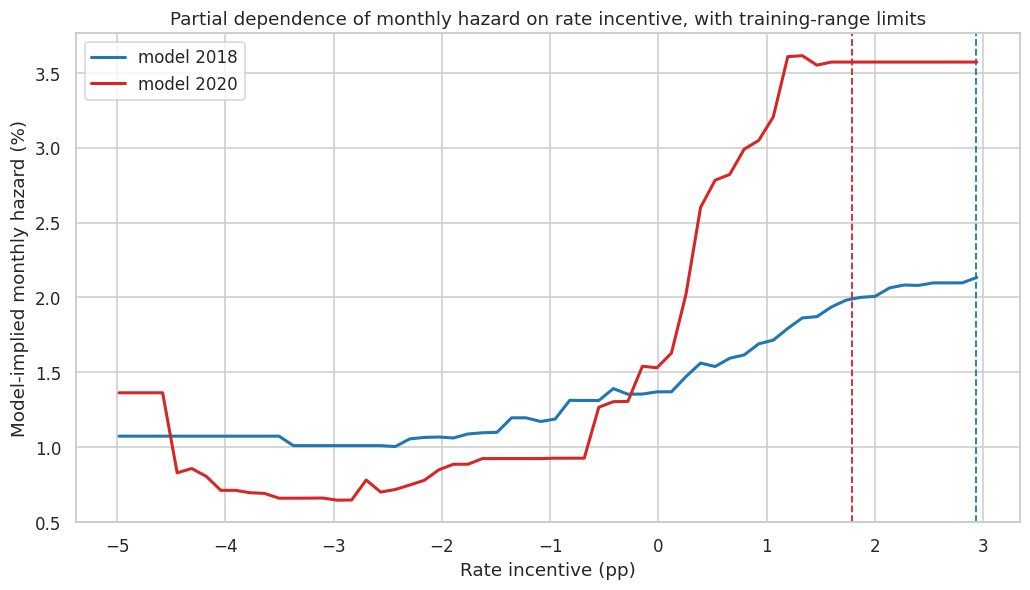

In [167]:
# @title **11.2 - The learned incentive curves, and where they stop**

# Partial dependence: sweep the incentive across a grid, average the model's
# predicted probability at every stop, and the result is the model's learned
# hazard-versus-incentive curve. Method note: the fast tree-traversal
# shortcut returns values on an offset log-odds scale, so the brute method -
# which averages actual predicted probabilities - is forced, over a 50,000-
# row random sample of the pooled test sets for tractability. Both models
# are swept over the same pooled sample, so each curve extends beyond its
# own training territory. The dashed vertical lines mark where each model's
# training data effectively ends (its 99.5th incentive percentile): a curve
# that flattens at its own line indicates a model extrapolating - answering
# beyond its training range with the last relationship it learned.

X_pool = pd.concat(
    [make_design(split[v]['test'], medians=logit_med[v])[0] for v in VINTAGES],
    ignore_index=True)
X_bg = X_pool.sample(50_000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
curves = {}
for v in VINTAGES:
    Xp = X_bg.reindex(columns=hgb_fit[v].feature_names_in_, fill_value=0)
    pd_res = partial_dependence(hgb_fit[v], Xp, features=['rate_incentive'],
                                percentiles=(0.002, 0.998), grid_resolution=60,
                                method='brute')
    grid = pd_res.get('grid_values', pd_res.get('values'))[0]
    avg  = pd_res['average'][0]
    curves[v] = pd.Series(avg, index=grid)

    tr_hi = split[v]['train']['rate_incentive'].quantile(0.995)
    ax.plot(grid, avg * 100, color=COL[v], lw=2, label=f'model {v}')
    ax.axvline(tr_hi, color=COL[v], lw=1.2, ls='--')

    near = lambda x: curves[v].iloc[np.argmin(np.abs(curves[v].index - x))]
    print(f'model {v}: training incentive runs to {tr_hi:+.2f} (99.5th pct) | '
          f'learned hazard at 0: {near(0)*100:.2f}% | at +1: {near(1)*100:.2f}% | '
          f'at +2: {near(2)*100:.2f}% | at +2.5: {near(2.5)*100:.2f}%')

ax.set_xlabel('Rate incentive (pp)')
ax.set_ylabel('Model-implied monthly hazard (%)')
ax.set_title('Partial dependence of monthly hazard on rate incentive, with training-range limits')
ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG}/fig7_pdp_incentive.png', dpi=150)
plt.show()


Two properties of these curves explain Section 10. First, the 2020 model's curve flattens at 3.57% - identical values at +2 and +2.5 - with the
flattening beginning near +1.3, inside its own training limit of +1.79: beyond the territory its regime demonstrated, the model repeats the last relationship it learned. The 2018 model's curve, by contrast, is still rising at +2.5 (2.10%), because its regime demonstrated that the response keeps strengthening. Second, above +1 the 2020 model's implied hazard exceeds the 2018 model's by roughly 1.5 percentage points (3.21% against 1.71% at +1; 3.57% against 2.01% at +2). This is the mechanism of the transfer failure measured in Section 10: a model calibrated under lock-in, asked about a refinancing wave, answers with an extrapolated plateau, and overstates prepayment in exactly the months that matter. A note on reading partial dependence: these levels average over all other features in the pooled sample and are not comparable to the raw bin rates of Section 8.1; the valid comparisons are each curve against its own training limit, and the two curves against each other.

### Section 11 - Where the transfer failure lives

Section 10 established that transferred models keep their ranking ability and lose their calibration. This section locates both facts in the fitted models themselves.

#### The two regimes produced different decision structures

Permutation importance shows the 2020 model depending overwhelmingly on a single variable - shuffling the rate incentive costs it 0.162 of AUC, more than every other feature combined - while the 2018 model distributes its reliance across loan size (0.049), streak position (0.048), loan age (0.036), and the incentive (0.021). The difference reflects the regimes,
not modelling choices: where refinancing was briefly economical, identifying that window is the whole task; where it was economical for years, the task is identifying which borrowers act, and when. This explains why ranking largely survives transfer - both models still order
in-the-money months above out-of-the-money months - while the structure built on top of that ordering differs.

#### The calibration failure is an extrapolation failure

The partial-dependence curves show each model's learned hazard-versus-incentive relationship ending where its training data ends. The 2020 model's curve flattens at 3.57% before its own training limit of +1.79 and answers every question beyond it with that plateau; the 2018
model's curve is still rising at +2.5. Above +1, the 2020 model's implied hazard exceeds the 2018 model's by roughly 1.5 percentage points, the
direct mechanism of the 1.29x overprediction measured in Section 10, and, in more extreme form, of the logit's 3.18x. A model asked about territory outside its training regime does not fail randomly: it repeats the last relationship it learned, and gives no signal that it is extrapolating.

#### Practical implications

These results give the transfer failure a structure that practitioners can act on: the risk is largest for models calibrated in low-activity regimes and deployed into high-activity ones, and it concentrates precisely where the incentive exceeds the training regime's experience. Monitoring a deployed model's inputs against its training range is a direct, low-cost safeguard that this analysis supports.

# **Section 12 - Exporting Figures and Tables**

Every figure and table in this project was saved to Drive at the moment it was produced, so nothing remains to generate. What this section owes the project is proof: a verification that every asset the paper depends on exists on disk, with its size and last-modified time on record. The notebook's final output is therefore a complete manifest of its own evidence.

For traceability to the accompanying paper: paper Figure 1 = fig1, Figure 2
= fig4, Figure 3 = fig5, Figure 4 = fig6, Figure 5 = fig7; paper Tables 1
and 2 = table1 and table2. Notebook figures 2 (survival) and 3 (incentive
paths) support the analysis but do not appear in the paper.

In [168]:
# @title **12.1 - Verify and inventory the paper's assets**

# Three asset groups are asserted - figures, tables, and fitted models - so
# a missing file stops the notebook here rather than surfacing during paper
# assembly. The data checkpoints are listed for completeness. Modification
# times are printed so the manifest also records when each asset was last
# regenerated.

ASSETS = {
    'figures': [f'{FIG}/fig1_hazard_vs_incentive.png',
                f'{FIG}/fig2_survival_by_age.png',
                f'{FIG}/fig3_incentive_paths.png',
                f'{FIG}/fig4_prepayment_calendar.png',
                f'{FIG}/fig5_calibration.png',
                f'{FIG}/fig6_importance.png',
                f'{FIG}/fig7_pdp_incentive.png'],
    'tables':  [f'{TAB}/table1_loan_characteristics.csv',
                f'{TAB}/table2_transfer_test.csv'],
    'models':  [f'{OUT}/models/models_2018.joblib',
                f'{OUT}/models/models_2020.joblib'],
}

CHECKPOINTS = [f'{OUT}/orig_{v}_clean.parquet'     for v in VINTAGES] + \
              [f'{OUT}/svcg_{v}_clean.parquet'     for v in VINTAGES] + \
              [f'{OUT}/target_{v}.parquet'         for v in VINTAGES] + \
              [f'{OUT}/panel_{v}.parquet'          for v in VINTAGES] + \
              [f'{OUT}/panel_features_{v}.parquet' for v in VINTAGES]

def report(path, required):
    exists = os.path.exists(path)
    if required:
        assert exists, f'MISSING asset: {path}'
    if exists:
        size_kb = os.path.getsize(path) / 1e3
        mtime = pd.Timestamp(os.path.getmtime(path), unit='s').strftime('%Y-%m-%d %H:%M')
        print(f'   {os.path.basename(path):<38} {size_kb:>9,.0f} KB   modified {mtime}')
    else:
        print(f'   {os.path.basename(path):<38} (not present)')

for group, paths in ASSETS.items():
    print(f'\n{group.upper()} ({len(paths)}):')
    for p in paths:
        report(p, required=True)

print(f'\nDATA CHECKPOINTS ({len(CHECKPOINTS)}):')
for p in CHECKPOINTS:
    report(p, required=False)

print('\nAll required assets verified. The paper draws on the figures and '
      'tables above; the models and checkpoints reproduce every number in them.')



FIGURES (7):
   fig1_hazard_vs_incentive.png                  93 KB   modified 2026-08-23 18:28
   fig2_survival_by_age.png                      83 KB   modified 2026-08-23 18:28
   fig3_incentive_paths.png                     184 KB   modified 2026-08-23 18:28
   fig4_prepayment_calendar.png                 111 KB   modified 2026-08-23 18:28
   fig5_calibration.png                         136 KB   modified 2026-08-23 18:29
   fig6_importance.png                           69 KB   modified 2026-08-23 18:32
   fig7_pdp_incentive.png                        87 KB   modified 2026-08-23 18:33

TABLES (2):
   table1_loan_characteristics.csv                0 KB   modified 2026-08-23 18:28
   table2_transfer_test.csv                       0 KB   modified 2026-08-23 18:30

MODELS (2):
   models_2018.joblib                     1,034,426 KB   modified 2026-08-23 18:29
   models_2020.joblib                     1,352,207 KB   modified 2026-08-23 18:29

DATA CHECKPOINTS (10):
   orig_2018_clean.parq